# COMP 472 Project (Fall 2026) - Group 1
## Decision Tree and Random Forest, written from scratch with NumPy

In this notebook we build two classifiers ourselves (no scikit-learn models):

1. a **CART decision tree** (with Gini or entropy), and
2. a **random forest** made of our own decision trees.

We use them on the two Kaggle tasks:

* **image**: 500 numeric features per picture, 50 classes
* **sentiment**: 768 numeric features per text (a text embedding), 3 classes

The notebook follows the questions we have to answer in the presentation:

| Presentation question | Section |
|---|---|
| How each algorithm works | 4.1 (tree), 7.1 (forest) |
| How we implemented each algorithm | 4.2, 4.3, 7.2, and the tests in 5 |
| Why we chose our hyperparameters | 6 (tree), 8 (forest) |
| How we built the validation set | 3 |
| How the algorithms compare | 9 |
| Differences between the image and sentiment tasks | 2 and 13 |
| Examples of model errors | 10 |
| Evidence of overfitting / underfitting | 6.1, 6.2, 9, 11 |
| How we picked the final Kaggle model | 14 |
| What we would improve with more time | 15 |
| Questions we expect from the TA | Appendix |

**Running it:** set `QUICK_RUN = True` in section 1 to check that every cell runs (a few minutes), then set it back to `False` for the real results.

Most of the runtime goes into section 8.

## 1. Setup, settings and loading the data

All the settings we might want to change are in the first cell, so we don't have to search the notebook for them.

* `SEED` fixes every random choice (validation split, bootstrap samples, random features), so running the notebook again gives exactly the same numbers.
* `N_JOBS` is how many CPU cores the random forest uses. The trees of a forest don't depend on each other, so we can grow several at the same time. This only changes the speed, not the results (each tree gets its own random seed, see 7.2).
* The `DT_*` and `RF_*` lists are the hyperparameter values we try. Why these values is explained in sections 6 and 8.

In [20]:
# ===== Section 1: setup, settings and loading the data =====
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba

# claude's idea: joblib runs the same function on several CPU cores at once. We only use it to grow trees in parallel
# (it is NOT a machine learning library). If it's not installed we just use a normal for loop.
try:
    from joblib import Parallel, delayed
    HAVE_JOBLIB = True
except ImportError:
    HAVE_JOBLIB = False

SEED = 42                 # fixed seed -> every "random" step (split, bootstrap, feature sampling) is repeatable
TASKS = ("image", "sentiment")
VAL_FRACTION = 0.20       # 80% train / 20% validation (section 3)
N_BINS = 64               # every feature is cut into 64 value groups ("bins"), see section 4.2
N_JOBS = 4                # CPU cores for training (Kaggle CPU notebooks have 4). 1 = one core, same results, slower

# QUICK_RUN = True  -> tiny search lists and very few trees, only to check that every cell runs.
# QUICK_RUN = False -> the real experiments (use this for the results we present).
QUICK_RUN = False

# ---- single decision tree search space (section 6) ----
DT_CRITERIA = ("gini", "entropy")                                    # the two impurity measures we compare
DT_LEAVES = (1, 10) if QUICK_RUN else (1, 2, 5, 10, 20, 50, 100)     # min_samples_leaf values
DT_SPLITS = (2, 50) if QUICK_RUN else (2, 5, 10, 20, 50, 100, 200)   # min_samples_split values
# max_depth has no list on purpose: we grow every tree fully and then "cut" it at depth 1, 2, 3, ... (section 6)

# ---- random forest search space (section 8) ----
RF_TUNE_TREES = 6 if QUICK_RUN else 30       # small forests are enough to COMPARE settings (section 8.1)
RF_FINAL_TREES = 12 if QUICK_RUN else 200    # n_estimators of the forest we keep (justified in section 8.2)
# We tune one hyperparameter at a time, in this order (section 8 explains why).
# max_features is written as a multiple of sqrt(number of features): 1 means the usual default sqrt(d).
RF_SEARCH = {
    "max_features":      (0.5, 1) if QUICK_RUN else (0.25, 0.5, 1, 2, 4),
    "min_samples_leaf":  (1, 5) if QUICK_RUN else (1, 3, 5, 10, 20),
    "max_depth":         (12, None) if QUICK_RUN else (8, 12, 16, 24, None),    # None = no depth limit
    "min_samples_split": (2, 10) if QUICK_RUN else (2, 5, 10, 20),
    "criterion":         ("gini", "entropy"),
    "bootstrap":         (True, False),
}
#TODO
LC_FRACTIONS = (0.25, 1.0) if QUICK_RUN else (0.1, 0.25, 0.5, 0.75, 1.0)     # learning curves (section 11)

# Optional extra experiments TODO
RUN_BIN_EXPERIMENT = not QUICK_RUN   # section 6.5: does cutting the features into 64 bins cost accuracy? 
COMPARE_WITH_SKLEARN = True          # section 5 claude's idea

# Same colours in every plot: blue = gini / decision tree, orange = entropy / random forest
BLUE, ORANGE, AQUA, VIOLET, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#8a8984"
TASK_COLORS = {"image": AQUA, "sentiment": VIOLET}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "font.size": 9})

# load the data
data_dir = next( Path("/kaggle/input").rglob("image_train.csv")).parent
working_dir = Path("/kaggle/working")

data = {}   # everything about one task is kept in data[task] (a dictionary), so the same code works for both tasks
for task in TASKS:
    # sorting by id fixes the row order, the random split in section 3 is always the same
    train_df = pd.read_csv(data_dir / f"{task}_train.csv").sort_values("id").reset_index(drop=True)
    test_df = pd.read_csv(data_dir / f"{task}_test.csv")
    feature_cols = list(train_df.columns.drop(["id", "label"]))
    assert set(test_df.columns) == set(feature_cols) | {"id"}, f"train/test columns differ for {task}"

    # float32 takes half the memory of float64 and is precise enough for these features (claude's idea)
    X = train_df[feature_cols].to_numpy(dtype=np.float32)
    X_test = test_df[feature_cols].to_numpy(dtype=np.float32)

    # TODO remove
    # our tree has no special handling for missing values, so we stop right away if there are any (claude)
    assert not np.isnan(X).any() and not np.isnan(X_test).any(), f"NaN values found in {task} data"

    # np.unique returns the sorted list of labels (`classes`)
    classes, y = np.unique(train_df["label"].to_numpy(), return_inverse=True)
    data[task] = dict(X=X, y=y, classes=classes, K=len(classes), X_test=X_test,
                      ids=train_df["id"].to_numpy(), test_ids=test_df["id"].to_numpy(), feature_cols=feature_cols)
    print(f"[{task}] train {X.shape}, test {X_test.shape}, {len(classes)} classes, first labels {classes[:5].tolist()}")

sample = pd.read_csv(data_dir / "sample_submission.csv")
print("sample_submission:", sample.shape, list(sample.columns))
print("training in parallel:", f"yes, on {N_JOBS} cores" if HAVE_JOBLIB and N_JOBS > 1 else "no (one core)")

[image] train (20000, 500), test (5000, 500), 50 classes, first labels [0, 1, 2, 3, 4]
[sentiment] train (12000, 768), test (5000, 768), 3 classes, first labels [0, 1, 2]
sample_submission: (10000, 2) ['id', 'label']
training in parallel: yes, on 4 cores


## 2. A first look at the data (and how the two tasks differ)

Before training anything um check how big each task is, how many rows each class has, and what the feature values look like. This is where the differences between the image task and the sentiment task first show up.

In [21]:
# ===== Section 2: describe the two datasets =====
rows = []
for task in TASKS:
    ds = data[task]
    X, X_test, y = ds["X"], ds["X_test"], ds["y"]
    counts = np.bincount(y)
    rows.append({
        "task": task,
        "training rows": len(X),
        "test rows": len(X_test),
        "features": X.shape[1],
        "classes": ds["K"],
        "rows per class (min / max)": f"{counts.min()} / {counts.max()}",
        "chance accuracy (1 / classes)": f"{1 / ds['K']:.1%}",
        "% of values exactly 0": f"{100 * (X == 0).mean():.1f}%",
        "min / max value": f"{X.min():.3f} / {X.max():.3f}",
        "mean / std of all values": f"{X.mean():.3f} / {X.std():.3f}",
        # if the test features had a very different average than the training features, our validation score
        # would not predict the Kaggle score well. This is the average gap over all features.
        #TODO delete 
        "avg |train mean - test mean| per feature": f"{np.abs(X.mean(axis=0) - X_test.mean(axis=0)).mean():.4f}",
    })
display(pd.DataFrame(rows).set_index("task").T)

task,image,sentiment
training rows,20000,12000
test rows,5000,5000
features,500,768
classes,50,3
rows per class (min / max),400 / 400,4000 / 4000
chance accuracy (1 / classes),2.0%,33.3%
% of values exactly 0,85.2%,0.0%
min / max value,0.000 / 0.923,-5.067 / 1.754
mean / std of all values,0.015 / 0.042,-0.013 / 0.323
avg |train mean - test mean| per feature,0.0005,0.0406


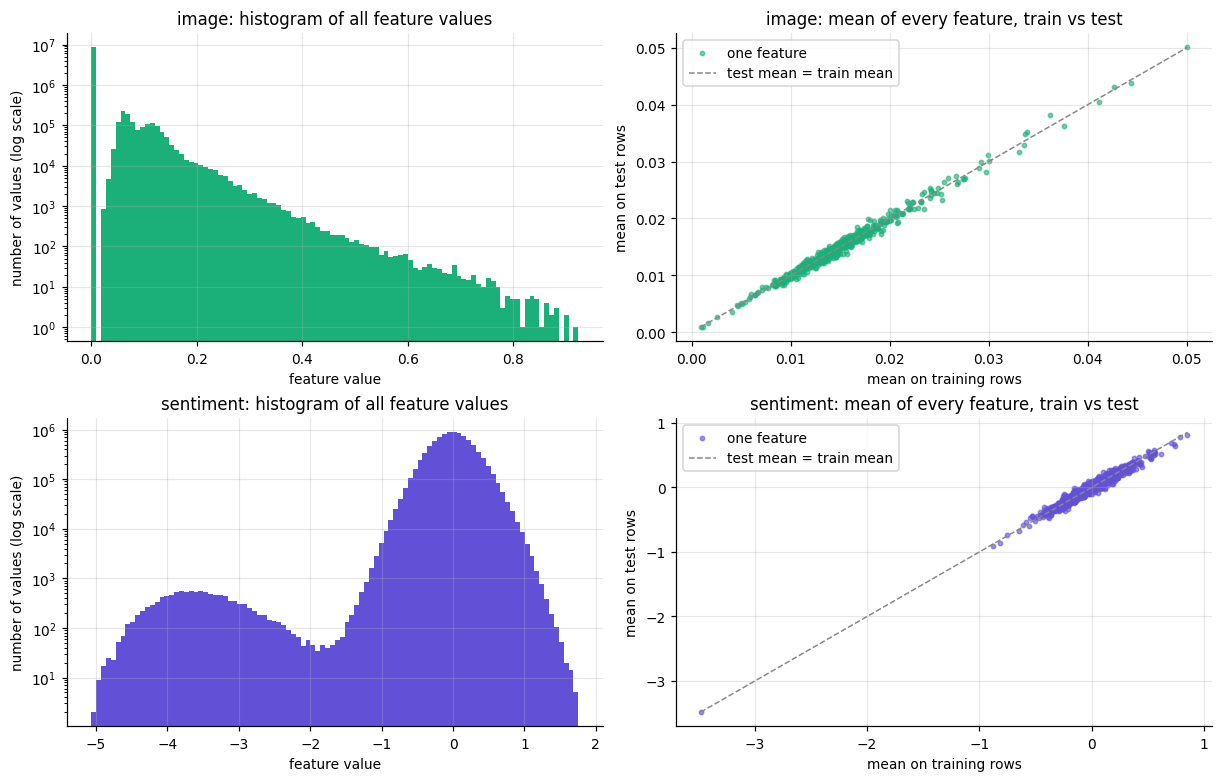

In [22]:
# Left: distribution of feature values (logarithmic scale).
# Right: compare feature averages between training and test data.

fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
for row, task in enumerate(TASKS):
    ds = data[task]
    ax = axes[row, 0]
    ax.hist(ds["X"].ravel(), bins=100, color=TASK_COLORS[task], log=True)
    ax.set(title=f"{task}: histogram of all feature values", xlabel="feature value", ylabel="number of values (log scale)")

    ax = axes[row, 1]
    train_mean, test_mean = ds["X"].mean(axis=0), ds["X_test"].mean(axis=0)
    ax.scatter(train_mean, test_mean, s=8, color=TASK_COLORS[task], alpha=0.6, label="one feature")
    lims = [min(train_mean.min(), test_mean.min()), max(train_mean.max(), test_mean.max())]
    ax.plot(lims, lims, color=GRAY, linestyle="--", linewidth=1, label="test mean = train mean")
    ax.set(title=f"{task}: mean of every feature, train vs test", xlabel="mean on training rows", ylabel="mean on test rows")
    ax.legend()
plt.show()

## 3. How we built the validation set

We can't use the Kaggle test set to choose hyperparameters (we don't have its labels and the number of submissions is limited), so we cut our own **validation set** out of the labeled training data:

* **80% train / 20% validation**, cut **separately for every class** (a *stratified* split). Every class keeps exactly the same share in both parts (image: 320 train + 80 validation rows per class, sentiment: 3200 + 800). With a plain random split some image classes could end up with 65 validation rows and others 95, just by luck.
* **One fixed split (seed 42)** for every experiment, so all models and settings are compared on exactly the same rows.
* The validation rows are **never used for training** while tuning. Even the bin cut points (section 4.2) come from the training part only, otherwise information about the validation rows would leak into the model.
* After all choices are made, the final models are retrained on **all** labeled rows (train + validation) for Kaggle (section 14).

**Why not k-fold cross-validation?** 5-fold CV gives a less noisy estimate but costs 5× the training time, and our forests already take minutes each. With 4000 (image) and 2400 (sentiment) validation rows a single hold-out set is already reasonably precise, and the forest gives us a free second estimate from its out-of-bag rows (section 7).

**How precise is a validation accuracy?** An accuracy $p$ measured on $n$ rows has a standard error of about $\sqrt{p(1-p)/n}$. The 95% interval is $\pm 1.96$ standard errors (printed below). Two settings whose accuracies differ by less than roughly this amount might only differ because of luck in which rows ended up in the validation set. We keep this in mind when we pick hyperparameters.

In [23]:
# ===== Section 3: validation split and the metrics we use ===== except the first function they are done by claude.
def stratified_split(y, val_fraction, seed):
    """Split the row positions into (train_indices, validation_indices).
    Every class is shuffled and cut on its own, so each class has the same share in both parts."""
    rng = np.random.default_rng(seed)
    val_parts = []
    for c in np.unique(y):                     # loop over every class (50 for image, 3 for sentiment)
        rows_of_c = np.flatnonzero(y == c)     # positions of all rows that have class c
        rng.shuffle(rows_of_c)                 # random order (always the same order because of the seed)
        n_val = int(round(len(rows_of_c) * val_fraction))
        val_parts.append(rows_of_c[:n_val])    # the first 20% of the shuffled rows go to validation
    is_val = np.zeros(len(y), dtype=bool)      # True = validation row, False = training row
    is_val[np.concatenate(val_parts)] = True
    return np.flatnonzero(~is_val), np.flatnonzero(is_val)


def accuracy(y_true, y_pred):
    """Share of rows predicted correctly (the Kaggle metric)."""
    return float((y_true == y_pred).mean())

# How much uncertainty is there in that measured accuracy?
def accuracy_ci(acc, n, z=1.96):
    # """Half-width of the 95% confidence interval of an accuracy measured on n rows (normal approximation).
    # Example: 25% accuracy on 4000 rows -> +-1.3%, so the true accuracy is probably between 23.7% and 26.3%."""
    return z * np.sqrt(acc * (1 - acc) / n)


def confusion_matrix(y_true, y_pred, n_classes):
    """cm[i, j] = number of rows whose true class is i and that were predicted as j (the diagonal = correct)."""
    # every (true, predicted) pair becomes the single number true*K + predicted, then bincount counts them all,
    return np.bincount(y_true * n_classes + y_pred, minlength=n_classes ** 2).reshape(n_classes, n_classes)


def macro_f1(cm):
    """F1 score of every class, then the plain average over classes (every class counts the same)."""
    true_pos = np.diag(cm).astype(float)
    precision = true_pos / np.maximum(cm.sum(axis=0), 1)   # column sums = how often each class was predicted
    recall = true_pos / np.maximum(cm.sum(axis=1), 1)      # row sums = how many rows each class really has
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return float(f1.mean())


for task in TASKS:
    ds = data[task]
    ds["tr"], ds["va"] = stratified_split(ds["y"], VAL_FRACTION, SEED)
    ds["y_tr"], ds["y_va"] = ds["y"][ds["tr"]], ds["y"][ds["va"]]
    assert len(np.intersect1d(ds["tr"], ds["va"])) == 0       # no row can be in both parts
    n_va = len(ds["va"])
    print(f"[{task}] {len(ds['tr'])} training rows, {n_va} validation rows -> 95% interval of a validation accuracy: "
          f"+-{accuracy_ci(0.25, n_va):.1%} around 25%, +-{accuracy_ci(0.5, n_va):.1%} around 50%")

[image] 16000 training rows, 4000 validation rows -> 95% interval of a validation accuracy: +-1.3% around 25%, +-1.5% around 50%
[sentiment] 9600 training rows, 2400 validation rows -> 95% interval of a validation accuracy: +-1.7% around 25%, +-2.0% around 50%


## 4. The decision tree

### 4.1 **Training (growing the tree)** is greedy and top-down:
1. Put all training rows in the root node.
2. For every feature and every possible threshold, imagine splitting the node in two and measure how "mixed" (impure) the two children would be.
3. Keep the split that makes the children the **purest** (biggest impurity decrease) and send the rows left/right.
4. Repeat for every child until a **stopping rule** says stop. Then the node becomes a leaf.


**Impurity measures.** With $p_k$ = share of class $k$ among the rows of a node:
* **Gini impurity**: $G = 1 - \sum_k p_k^2$. It's the probability that two rows drawn at random from the node have different classes. 0 = pure node.
* **Entropy**: $H = -\sum_k p_k \log_2 p_k$ (in bits). 0 = pure node, maximum $\log_2 K$ when all classes are equally common.


[Text(0.5, 1.0, 'Gini vs Entropy (2 classes)'),
 Text(0.5, 0, 'Share of class 1 (p)'),
 Text(0, 0.5, 'Impurity (scaled)')]

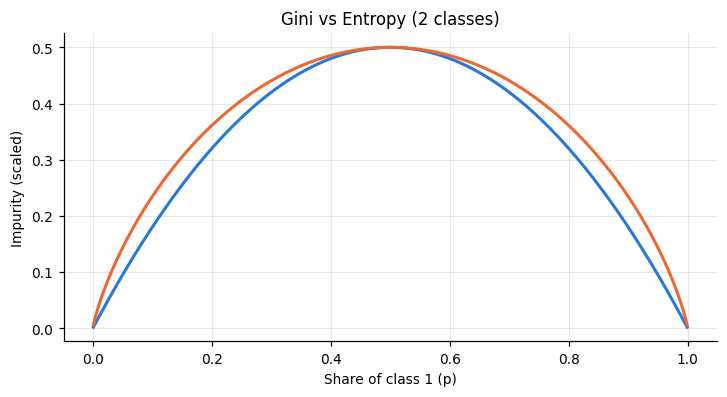

In [25]:
# The impurity measures for a node with 2 classes, as a function of p = share of class 1.
# This is the picture we use in the presentation to explain gini vs entropy.
p = np.linspace(0.001, 0.999, 300)

gini = 1 - p**2 - (1 - p)**2
entropy = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

fig, ax = plt.subplots(figsize=(6.5, 3.5), layout="constrained")

ax.plot(p, gini, color=BLUE, label="Gini")
ax.plot(p, entropy / 2, color=ORANGE, label="Entropy / 2 (scaled)")

ax.set(
    title="Gini vs Entropy (2 classes)",
    xlabel="Share of class 1 (p)",
    ylabel="Impurity (scaled)")

In [26]:
# ===== Section 4.2: quantile binning =====
class QuantileBinner:
    """Turns every feature into a bin number between 0 and n_bins-1."""

    def __init__(self, n_bins=64):
        self.n_bins = n_bins
        self.edges = None        # the cut points of every feature

    def fit(self, X):
        # 63 cut points per feature, at the 1/64, 2/64, ..., 63/64 percentiles of the training values
        percentiles = np.linspace(0.0, 1.0, self.n_bins + 1)[1:-1]
        self.edges = np.quantile(X, percentiles, axis=0)
        return self

    def transform(self, X):
        Xb = np.empty(X.shape, dtype=np.uint8)       # uint8 = small whole numbers (0..255), saves memory
        for j in range(X.shape[1]):
            # bin number = how many cut points are smaller than the value
            Xb[:, j] = np.searchsorted(self.edges[:, j], X[:, j], side="left")
        return Xb


# Bin the training and validation rows. The cut points are learned from the TRAINING rows only (no leakage).
for task in TASKS:
    ds = data[task]
    ds["binner"] = QuantileBinner(N_BINS).fit(ds["X"][ds["tr"]])
    ds["Xb_tr"] = ds["binner"].transform(ds["X"][ds["tr"]])
    ds["Xb_va"] = ds["binner"].transform(ds["X"][ds["va"]])
    print(f"[{task}] binned training data: {ds['Xb_tr'].shape}")

[image] binned training data: (16000, 500)
[sentiment] binned training data: (9600, 768)


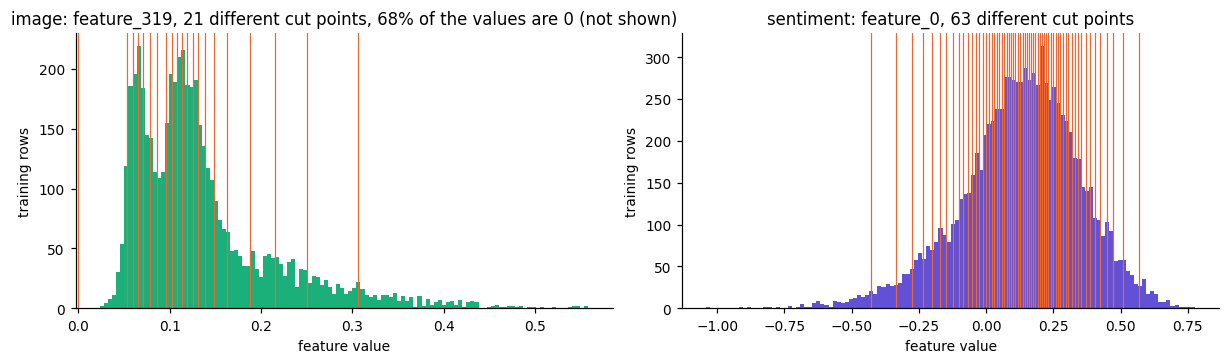

In [27]:
# Picture of the binning for one feature of each task: histogram of the real values with the 63 cut points
# (orange lines). Where there are many rows, the cut points are close together (equal-count bins).
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), layout="constrained")
for ax, task in zip(axes, TASKS):
    ds = data[task]
    X_train = ds["X"][ds["tr"]]
    j = int(np.argmax([len(np.unique(ds["Xb_tr"][:, f])) for f in range(X_train.shape[1])]))  # a feature using many bins
    values = X_train[:, j]
    zero_share = np.mean(values == 0)
    shown = values[values > 0] if zero_share > 0.2 else values   # sparse feature: hide the zeros, their bar would squash the plot
    ax.hist(shown, bins=120, range=(shown.min(), np.quantile(shown, 0.999)), color=TASK_COLORS[task])
    edges = np.unique(ds["binner"].edges[:, j])                  # repeated cut points (inside the zeros) drawn once
    for edge in edges:
        ax.axvline(edge, color=ORANGE, linewidth=0.8)
    ax.grid(False)
    note = f", {zero_share:.0%} of the values are 0 (not shown)" if zero_share > 0.2 else ""
    ax.set(title=f"{task}: {ds['feature_cols'][j]}, {len(edges)} different cut points{note}",
           xlabel="feature value", ylabel="training rows")
plt.show()


### 4.3 Decision Tree Implementation: Efficient Split Selection

Our Decision Tree is implemented using NumPy arrays to store the nodes, their splitting features, thresholds, children, and class probabilities.

**Tree construction:**
- The tree starts at the root and grows using a stack instead of recursion.
- A node stops splitting when it reaches `max_depth`, has too few samples, or contains only one class.
- Otherwise, the algorithm searches for the best feature and threshold to split the node.

**Finding the best split:**
1. Build a histogram counting the samples of each class in each feature bin.
2. Use cumulative sums to calculate how many samples would go to the left and right children for each possible split.
3. Calculate the weighted Gini impurity or entropy for each split.
4. Select the split with the lowest weighted impurity, provided it satisfies the minimum leaf size.

**Prediction:** Each sample moves through the tree according to the splitting conditions until it reaches a leaf. The predicted class is the most common class in that leaf.

**Feature importance:** Features receive higher importance when their splits produce larger reductions in impurity, especially when those splits affect many samples.

**Optimization:** NumPy vectorization, histograms, and cumulative sums allow us to evaluate many possible splits efficiently without repeatedly looping through individual samples.


In [28]:
# ===== Section 4.3: our decision tree =====
def _xlogx(a):
    """a * log2(a) with 0 * log2(0) = 0. Used in the entropy formulas (a is a count, so a >= 0)."""
    return a * np.log2(np.maximum(a, 1))      # log2(max(a, 1)) is 0 when a = 0, so 0 * log(0) comes out as 0


class DecisionTree:
    """CART decision tree for already-binned features (uint8 values 0..n_bins-1)."""

    def __init__(self, n_classes, n_bins=64, criterion="gini", max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, min_gain=0.0, max_features=None, rng=None):
        assert criterion in ("gini", "entropy"), "criterion must be 'gini' or 'entropy'"
        self.K = n_classes
        self.B = n_bins
        self.criterion = criterion
        self.max_depth = np.inf if max_depth is None else max_depth   # None = no depth limit
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_gain = min_gain              # a split must decrease the impurity by more than this
        self.max_features = max_features      # None = look at every feature at every split (a normal tree).
                                              # A number m = look at m random features per split (random forest)
        self.rng = rng if rng is not None else np.random.default_rng(0)

    # ------------------------------------------------------------------ training
    def fit(self, Xb, y, rows=None):
        """Grow the tree.
        Xb: (n, d) binned features. y: (n,) class numbers 0..K-1.
        rows: which rows of Xb to train on. The same row may appear several times: the random forest passes its
              bootstrap sample here, so we never have to copy the data for every tree."""
        n, d = Xb.shape
        self.d = d
        if rows is None:
            rows = np.arange(n)

        # one list entry per node, turned into NumPy arrays at the end
        feature, thr, left, right, node_depth, node_rows, node_counts = [], [], [], [], [], [], []

        def new_node(depth, counts):
            feature.append(-1)           # -1 = no question here (a leaf). Changed later if the node gets split
            thr.append(-1)
            left.append(-1)
            right.append(-1)
            node_depth.append(depth)
            node_rows.append(int(counts.sum()))
            node_counts.append(counts)   # how many training rows of each class reach this node
            return len(feature) - 1

        stack = [(new_node(0, np.bincount(y[rows], minlength=self.K)), rows)]   # (node id, rows that reach it)
        while stack:
            node, rows_n = stack.pop()
            counts, depth, n_node = node_counts[node], node_depth[node], len(rows_n)

            # Stopping rules: if any of them fails, the node stays a leaf
            can_split = (depth < self.max_depth                   # max_depth
                         and n_node >= self.min_samples_split     # min_samples_split
                         and n_node >= 2 * self.min_samples_leaf  # both children need min_samples_leaf rows
                         and counts.max() < n_node)               # not pure (more than one class in the node)
            if not can_split:
                continue
            split = self._best_split(Xb, y, rows_n, counts)
            if split is None:            # no allowed split decreases the impurity -> leaf
                continue

            f, b, gain = split           # the question is "bin of feature f <= b ?"
            goes_left = Xb[rows_n, f] <= b
            rows_l, rows_r = rows_n[goes_left], rows_n[~goes_left]
            l = new_node(depth + 1, np.bincount(y[rows_l], minlength=self.K))
            r = new_node(depth + 1, np.bincount(y[rows_r], minlength=self.K))
            feature[node], thr[node], left[node], right[node] = f, b, l, r
            stack.append((l, rows_l))
            stack.append((r, rows_r))

        # lists -> arrays, so that prediction can handle all rows at the same time
        self.feature = np.array(feature, dtype=np.int64)
        self.thr = np.array(thr, dtype=np.int64)
        self.left = np.array(left, dtype=np.int64)
        self.right = np.array(right, dtype=np.int64)
        self.node_depth = np.array(node_depth, dtype=np.int64)
        self.node_rows = np.array(node_rows, dtype=np.int64)
        counts = np.array(node_counts, dtype=np.float32)
        self.value = counts / counts.sum(axis=1, keepdims=True)       # class counts -> class shares
        return self

    def _best_split(self, Xb, y, rows, counts):
        """Best (feature, bin, impurity decrease) for the rows of one node, or None if there is no useful split."""
        n = len(rows)

        # Which features may we look at? All of them for a normal tree, a random subset in a random forest.
        if self.max_features is None or self.max_features >= self.d:
            feats = np.arange(self.d)
        else:
            feats = self.rng.choice(self.d, self.max_features, replace=False)
        f = len(feats)

        # Speed-up: only the classes present in this node matter. `remap` renames them 0..k-1.
        present = np.flatnonzero(counts)
        k = len(present)
        remap = np.zeros(self.K, dtype=np.int64)
        remap[present] = np.arange(k)
        yk = remap[y[rows]]
        c = counts[present]                                      # class counts of the node itself

        # Step 1: hist[feature, bin, class] = how many rows of the node fall in that cell.
        # Each (row, feature) pair gets one unique cell number, then a single bincount counts every cell.
        sub = Xb[rows[:, None], feats]                           # (n, f) bin numbers of the chosen features
        cell = (np.arange(f) * self.B + sub) * k + yk[:, None]   # (n, f) cell numbers
        hist = np.bincount(cell.ravel(), minlength=f * self.B * k).reshape(f, self.B, k)

        # Step 2: splitting "after bin b" sends bins 0..b left. A cumulative sum over the bins gives the left class
        # counts for every b at once, and right = node - left. ("after the last bin" is not a split, so it's dropped)
        L = np.cumsum(hist, axis=1)[:, :-1, :]                   # (f, B-1, k)
        R = c - L
        n_left = L.sum(axis=2)                                   # (f, B-1)
        n_right = n - n_left

        # Step 3: impurity of the children for every split, as n_L * I(left) + n_R * I(right)
        if self.criterion == "gini":
            # n_L * Gini(left) = n_L - sum_k L_k^2 / n_L   (same for the right side)
            with np.errstate(divide="ignore", invalid="ignore"):    # empty children divide by 0; removed below
                children = n - (L * L).sum(axis=2) / n_left - (R * R).sum(axis=2) / n_right
            parent = n - (c * c).sum() / n                          # n * Gini(node)
        else:
            # n_L * H(left) = n_L log2(n_L) - sum_k L_k log2(L_k)
            children = (_xlogx(n_left) - _xlogx(L).sum(axis=2)
                        + _xlogx(n_right) - _xlogx(R).sum(axis=2))
            parent = _xlogx(n) - _xlogx(c).sum()                     # n * H(node)

        # min_samples_leaf: both children must keep enough rows (this also throws away the empty-child splits)
        valid = (n_left >= self.min_samples_leaf) & (n_right >= self.min_samples_leaf)
        children = np.where(valid, children, np.inf)

        best_index = int(np.argmin(children))     # least impure children = biggest decrease (first one wins a tie)
        if not np.isfinite(children.flat[best_index]):            # no valid split at all
            return None
        gain = (parent - children.flat[best_index]) / n           # the impurity decrease (Delta in section 4.1)
        if gain <= self.min_gain + 1e-12:                         # tiny tolerance for floating point rounding
            return None
        feat_slot, bin_b = divmod(best_index, self.B - 1)
        return int(feats[feat_slot]), int(bin_b), float(gain)

    # ---------------------------------------------------------------- prediction
    def predict_proba(self, Xb, max_depth=None):
        """Class shares of the leaf every row ends up in, shape (n_rows, K).
        max_depth: stop each row after this many questions (as if the tree had been grown with that max_depth)."""
        n = len(Xb)
        row_ids = np.arange(n)
        node = np.zeros(n, dtype=np.int64)         # every row starts at the root
        while True:
            f = self.feature[node]                 # the question of each row's current node (-1 at a leaf)
            active = f >= 0                        # rows that still have a question to answer
            if max_depth is not None:
                active &= self.node_depth[node] < max_depth
            if not active.any():
                break
            # (rows at a leaf have f = -1, which reads the last column; that answer is thrown away on the next line)
            goes_left = Xb[row_ids, f] <= self.thr[node]
            node = np.where(active, np.where(goes_left, self.left[node], self.right[node]), node)
        return self.value[node]

    def predict(self, Xb, max_depth=None):
        """Predicted class number = the class with the biggest share in the leaf."""
        return self.predict_proba(Xb, max_depth).argmax(axis=1)

    # ---------------------------------------------------------------- information about the tree


    @property
    def n_leaves(self):
        return int((self.feature < 0).sum())

    @property
    def depth(self):
        return int(self.node_depth.max())

    def n_leaves_at_depth(self, max_depth):
        """How many leaves the tree would have if it was cut at max_depth (for the plots in section 6)."""
        is_leaf = (self.feature < 0) | (self.node_depth == max_depth)
        return int((is_leaf & (self.node_depth <= max_depth)).sum())

## 5. Testing our implementation

Since we wrote the tree ourselves, we check it against slow but obviously-correct code, on a small piece of real data (the first 400 image rows):

1. **Binning:** "bin ≤ b" must give the same answer as "real value ≤ cut point b", for every feature and every cut point.
2. **Best split:** the split chosen by our fast histogram code must have the same impurity decrease as the best split found by brute force (trying every feature and threshold one by one with the textbook formulas). Checked for **Gini and entropy**.
3. **Depth cutting:** a tree grown with `max_depth = d` must give exactly the same predictions as a fully grown tree cut at depth d. Section 6 relies on this.
4. **Fully grown tree:** with no limits, the tree keeps splitting until every leaf is pure, so it should get 100% on its own training rows.
5. **Reference check:** we train scikit-learn's `DecisionTreeClassifier` on the same binned data with the same settings and compare the predictions. scikit-learn is **only** used here as a check of our code; none of our results or submissions use it.

In [29]:
# ===== Section 5: tests =====
def gini_impurity(counts):
    """Gini impurity straight from the definition (slow, only for the tests)."""
    total = counts.sum()
    return 0.0 if total == 0 else 1.0 - ((counts / total) ** 2).sum()


def entropy_impurity(counts):
    """Entropy in bits straight from the definition (slow, only for the tests)."""
    total = counts.sum()
    if total == 0:
        return 0.0
    p = counts[counts > 0] / total
    return float(-(p * np.log2(p)).sum())

# the first 400 image training rows, including all 500 features of each row
X_t = data["image"]["X"][:400]      # a small piece of the real data, so the brute force loops finish quickly
y_t = data["image"]["y"][:400]
K_t = data["image"]["K"]
n_t, d_t = X_t.shape
binner_t = QuantileBinner(N_BINS).fit(X_t)
Xb_t = binner_t.transform(X_t)
Xb_other = binner_t.transform(data["image"]["X"][400:1400])    # rows the small trees did not train on

# Check 2: brute force best first split, for both criteria
def impurity_decrease(mask, impurity):
    """Impurity decrease when the 400 rows are split by `mask` (True = goes left), from the definition."""
    n_left = int(mask.sum())
    children = (n_left * impurity(np.bincount(y_t[mask], minlength=K_t))
                + (n_t - n_left) * impurity(np.bincount(y_t[~mask], minlength=K_t))) / n_t
    return impurity(np.bincount(y_t, minlength=K_t)) - children


for criterion, impurity in (("gini", gini_impurity), ("entropy", entropy_impurity)):
    best = -1.0
    for j in range(d_t):
        for b in range(N_BINS - 1):
            mask = Xb_t[:, j] <= b
            if 0 < mask.sum() < n_t:               # both sides need at least one row
                best = max(best, impurity_decrease(mask, impurity))
    stump = DecisionTree(K_t, N_BINS, criterion=criterion, max_depth=1).fit(Xb_t, y_t)    # a tree with one question
    ours = impurity_decrease(Xb_t[:, stump.feature[0]] <= stump.thr[0], impurity)
    print(f"check 2 ({criterion}): best decrease by brute force {best:.6f}, chosen by our tree {ours:.6f}")
    assert abs(best - ours) < 1e-9, "the fast split search disagrees with brute force"
print("check 2 passed for gini and entropy")

# Check 3: growing with max_depth=d gives the same tree as cutting a full tree at depth d
for criterion in DT_CRITERIA:
    full = DecisionTree(K_t, N_BINS, criterion=criterion).fit(Xb_t, y_t)
    for depth in (1, 2, 3, 5, 8):
        small = DecisionTree(K_t, N_BINS, criterion=criterion, max_depth=depth).fit(Xb_t, y_t)
        assert np.array_equal(small.predict_proba(Xb_t), full.predict_proba(Xb_t, max_depth=depth)), \
            f"{criterion}: depth {depth} differs"
print(f"check 3 passed for {DT_CRITERIA} at depths (1, 2, 3, 5, 8): "
      f"a tree grown with max_depth=d = the full tree cut at depth d")

# Check 4: a fully grown tree memorises its training rows (100% on the rows it was trained on)
print(f"check 4: fully grown tree -> accuracy on its own 400 training rows = {accuracy(y_t, full.predict(Xb_t)):.3f} "
      f"({full.n_leaves} leaves, depth {full.depth})")

check 2 (gini): best decrease by brute force 0.017045, chosen by our tree 0.017045
check 2 (entropy): best decrease by brute force 0.184157, chosen by our tree 0.184157
check 2 passed for gini and entropy
check 3 passed for ('gini', 'entropy') at depths (1, 2, 3, 5, 8): a tree grown with max_depth=d = the full tree cut at depth d
check 4: fully grown tree -> accuracy on its own 400 training rows = 1.000 (266 leaves, depth 18)


In [30]:
# TODO maybe remove
# Check 5: compare with scikit-learn's tree on the real binned sentiment data. ONLY a sanity check
if COMPARE_WITH_SKLEARN:
    try:
        from sklearn.tree import DecisionTreeClassifier
    except ImportError:
        DecisionTreeClassifier = None
        print("scikit-learn is not installed, check 5 skipped")
    if DecisionTreeClassifier is not None:
        ds = data["sentiment"]
        for criterion in DT_CRITERIA:
            ours = DecisionTree(ds["K"], N_BINS, criterion=criterion, max_depth=6, min_samples_leaf=5).fit(ds["Xb_tr"], ds["y_tr"])
            ref = DecisionTreeClassifier(criterion=criterion, max_depth=6, min_samples_leaf=5, random_state=0)
            ref.fit(ds["Xb_tr"], ds["y_tr"])
            p_ours, p_ref = ours.predict(ds["Xb_va"]), ref.predict(ds["Xb_va"])
            print(f"check 5 ({criterion}): validation accuracy ours {accuracy(ds['y_va'], p_ours):.4f}, "
                  f"scikit-learn {accuracy(ds['y_va'], p_ref):.4f}, same prediction for {np.mean(p_ours == p_ref):.1%} of rows")

check 5 (gini): validation accuracy ours 0.4838, scikit-learn 0.4829, same prediction for 99.9% of rows
check 5 (entropy): validation accuracy ours 0.4833, scikit-learn 0.4833, same prediction for 100.0% of rows


##  6. Decision Tree Hyperparameter Tuning

**What we tune and why.** We test different hyperparameters to find the best Decision Tree while avoiding underfitting and overfitting. We tune:
- `criterion` (Gini / entropy): compare Gini and entropy.
- `max_depth`: control how deep the tree can grow (the main complexity changer).
- `min_samples_leaf`: control the minimum number of samples in each leaf.
- `min_samples_split`: test separately in Section 6.3.

**The depth trick: why there is no loop over `max_depth`.** Instead of training a new tree for every `max_depth`, we grow one tree for each combination of criterion and minimum leaf size, then evaluate its predictions at different depths. This allows us to test all depths while training only 14 trees per task.

**How we pick the winner:** we select the hyperparameter combination with the highest **validation** accuracy. If multiple combinations tie, we prefer the tree with fewer leaves.

In [31]:
# ===== Section 6.1: full grid for the single tree (criterion x min_samples_leaf x every max_depth) =====

def run_in_parallel(func, jobs): #claude's code 
    """Call func(**job) for every dictionary in `jobs`, on N_JOBS cores if possible. Results come back in order."""
    if HAVE_JOBLIB and N_JOBS > 1:
        return Parallel(n_jobs=N_JOBS)(delayed(func)(**job) for job in jobs)
    return [func(**job) for job in jobs]

def warn_if_edge(name, value, values):
    #TODO maybe delete and see it ...
    """If the best value is the biggest one we tried (or the smallest, for max_features / max_depth), the real best
    could be outside our range, so we print a note. Then it's worth adding more values to the list in section 1."""
    values = list(values)
    if isinstance(value, (bool, str)) or value is None or len(values) < 3:
        return
    if value == values[-1]:
        print(f"   NOTE: {name} = {value} is the LARGEST value we tried, a bigger value might be even better")
    elif value == values[0] and name in ("max_features", "max_depth"):
        print(f"   NOTE: {name} = {value} is the SMALLEST value we tried, a smaller value might be even better")


def depth_curve(Xb_tr, y_tr, Xb_va, y_va, K, criterion, min_samples_leaf):
    """Grow one full tree, then score it cut at every depth from 1 to its full depth. Returns one row per depth."""
    t0 = time.time()
    tree = DecisionTree(K, N_BINS, criterion=criterion, min_samples_leaf=min_samples_leaf).fit(Xb_tr, y_tr)
    seconds = round(time.time() - t0, 1)
    rows = []
    for depth in range(1, tree.depth + 1):
        rows.append(dict(criterion=criterion, min_samples_leaf=min_samples_leaf, max_depth=depth,
                         leaves=tree.n_leaves_at_depth(depth),
                         train_acc=accuracy(y_tr, tree.predict(Xb_tr, max_depth=depth)),
                         val_acc=accuracy(y_va, tree.predict(Xb_va, max_depth=depth)),
                         full_tree_seconds=seconds))
    return rows


dt_grid = {}
for task in TASKS:
    ds = data[task]
    t0 = time.time()
    jobs = [dict(Xb_tr=ds["Xb_tr"], y_tr=ds["y_tr"], Xb_va=ds["Xb_va"], y_va=ds["y_va"], K=ds["K"],
                 criterion=criterion, min_samples_leaf=leaf)
            for criterion in DT_CRITERIA for leaf in DT_LEAVES]
    grid = pd.DataFrame([row for rows in run_in_parallel(depth_curve, jobs) for row in rows])
    dt_grid[task] = grid

    # best = highest validation accuracy, ties -> fewer leaves (the simpler tree)
    best = grid.sort_values(["val_acc", "leaves"], ascending=[False, True]).iloc[0]
    ds["dt_best"] = dict(criterion=best["criterion"], max_depth=int(best["max_depth"]),
                         min_samples_leaf=int(best["min_samples_leaf"]), min_samples_split=2)
    print(f"[{task}] {len(jobs)} full trees -> {len(grid)} (criterion, min_samples_leaf, max_depth) combinations "
          f"scored in {time.time() - t0:.0f}s")
    print(f"[{task}] best: {ds['dt_best']} -> validation {best['val_acc']:.4f} "
          f"(+-{accuracy_ci(best['val_acc'], len(ds['y_va'])):.4f}), training {best['train_acc']:.4f}, {best['leaves']} leaves")
    warn_if_edge("min_samples_leaf", ds["dt_best"]["min_samples_leaf"], DT_LEAVES)

    # best depth of every (criterion, min_samples_leaf) pair: this table goes in the presentation
    summary = grid.loc[grid.groupby(["criterion", "min_samples_leaf"])["val_acc"].idxmax()]
    summary = summary.rename(columns={"max_depth": "best max_depth", "full_tree_seconds": "seconds (full tree)"})
    display(summary.round(4).reset_index(drop=True))

[image] 14 full trees -> 788 (criterion, min_samples_leaf, max_depth) combinations scored in 229s
[image] best: {'criterion': 'gini', 'max_depth': 48, 'min_samples_leaf': 20, 'min_samples_split': 2} -> validation 0.1250 (+-0.0102), training 0.2579, 607 leaves


,criterion,min_samples_leaf,best max_depth,leaves,train_acc,val_acc,seconds (full tree)
0,entropy,1,35,9356,0.9818,0.1055,148.0
1,entropy,2,35,5827,0.7279,0.1040,123.5
2,entropy,5,29,2375,0.4447,0.1035,85.0
3,entropy,10,29,1173,0.2929,0.1028,62.5
4,entropy,20,35,607,0.2141,0.0998,40.4
5,entropy,50,18,201,0.1479,0.1020,25.7
6,entropy,100,18,107,0.1256,0.0930,15.8
7,gini,1,60,8342,0.9309,0.1125,113.7
8,gini,2,47,4848,0.6514,0.1080,98.6
9,gini,5,49,2318,0.4776,0.1222,62.2


[sentiment] 14 full trees -> 249 (criterion, min_samples_leaf, max_depth) combinations scored in 35s
[sentiment] best: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 20, 'min_samples_split': 2} -> validation 0.5092 (+-0.0200), training 0.5941, 116 leaves


,criterion,min_samples_leaf,best max_depth,leaves,train_acc,val_acc,seconds (full tree)
0,entropy,1,7,125,0.6022,0.4983,20.9
1,entropy,2,7,125,0.6022,0.4983,20.3
2,entropy,5,7,125,0.6021,0.4983,17.0
3,entropy,10,7,123,0.6003,0.5012,12.0
4,entropy,20,7,116,0.5941,0.5092,7.3
5,entropy,50,7,96,0.5808,0.5038,3.6
6,entropy,100,7,68,0.5573,0.4975,1.6
7,gini,1,7,128,0.6291,0.4846,13.2
8,gini,2,7,128,0.6288,0.4846,12.0
9,gini,5,6,64,0.5773,0.4838,9.2


### 6.1 Overfitting and underfitting as the tree gets deeper

The top row shows accuracy against `max_depth` with no other limit (`min_samples_leaf = 1`): **dashed = training rows, solid = validation rows** (the shaded band is the 95% interval). The bottom row shows how many leaves the tree has, for every `min_samples_leaf`.

* **Left side (shallow trees): underfitting.** Training and validation accuracy are both low and close to each other: the tree is too simple to separate the classes.
* **Right side (deep trees): overfitting.** Training accuracy keeps climbing towards 100% (the tree ends up with leaves that contain only one or two rows, i.e. it memorises the training set) but validation accuracy stops improving or goes down.
* The best depth is the peak of the validation curve, between these two regions.
* Bottom row: `min_samples_leaf` puts a hard cap on the size of the tree (at most n / min_samples_leaf leaves), which is why it works against overfitting.

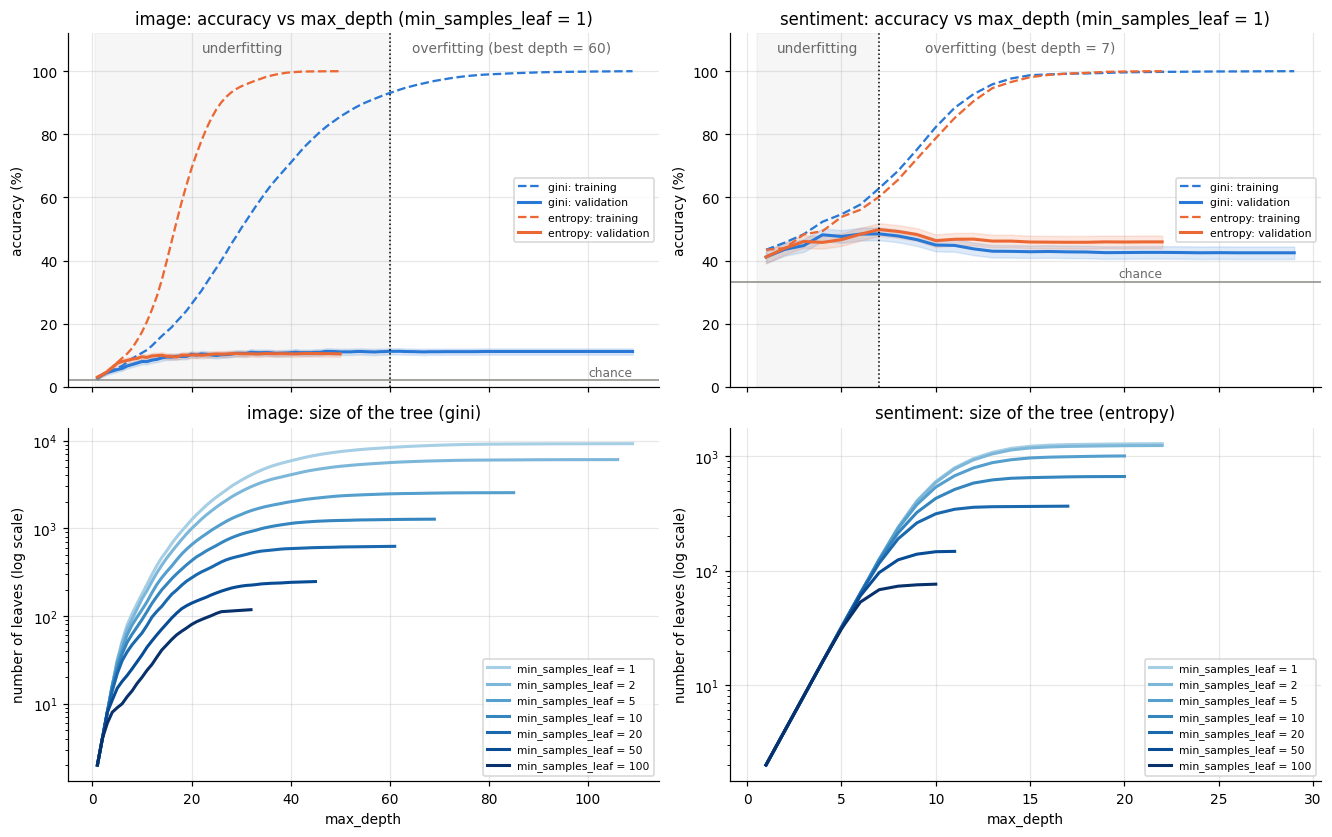

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), layout="constrained", sharex="col")
for col, task in enumerate(TASKS):
    ds, grid = data[task], dt_grid[task]

    # ---- top: accuracy vs depth for both criteria, min_samples_leaf = 1 ----
    ax = axes[0, col]
    for criterion, color in zip(DT_CRITERIA, (BLUE, ORANGE)):
        g = grid[(grid["criterion"] == criterion) & (grid["min_samples_leaf"] == 1)]
        ax.plot(g["max_depth"], 100 * g["train_acc"], "--", color=color, linewidth=1.5, label=f"{criterion}: training")
        ax.plot(g["max_depth"], 100 * g["val_acc"], "-", color=color, label=f"{criterion}: validation")
        ci = 100 * accuracy_ci(g["val_acc"], len(ds["y_va"]))
        ax.fill_between(g["max_depth"], 100 * g["val_acc"] - ci, 100 * g["val_acc"] + ci, color=color, alpha=0.15)
    g = grid[(grid["criterion"] == ds["dt_best"]["criterion"]) & (grid["min_samples_leaf"] == 1)]
    best_depth, last_depth = int(g.loc[g["val_acc"].idxmax(), "max_depth"]), int(g["max_depth"].max())
    ax.axvline(best_depth, color="black", linestyle=":", linewidth=1)
    ax.axhline(100 / ds["K"], color=GRAY, linewidth=1)
    ax.text(last_depth, 100 / ds["K"] + 1.5, "chance", ha="right", fontsize=8, color="dimgray")
    ax.axvspan(0.5, best_depth, color=GRAY, alpha=0.07)
    ax.text((0.5 + best_depth) / 2, 106, "underfitting", ha="center", fontsize=9, color="dimgray")
    ax.text((best_depth + last_depth) / 2, 106, f"overfitting (best depth = {best_depth})", ha="center", fontsize=9, color="dimgray")
    ax.set_ylim(0, 112)
    ax.set_yticks(range(0, 101, 20))
    ax.set(title=f"{task}: accuracy vs max_depth (min_samples_leaf = 1)", ylabel="accuracy (%)")
    ax.legend(fontsize=7, loc="center right")

    # ---- bottom: number of leaves vs depth, for every min_samples_leaf ----
    ax = axes[1, col]
    shades = plt.cm.Blues(np.linspace(0.35, 1.0, len(DT_LEAVES)))
    criterion = ds["dt_best"]["criterion"]
    for leaf, shade in zip(DT_LEAVES, shades):
        g = grid[(grid["criterion"] == criterion) & (grid["min_samples_leaf"] == leaf)]
        ax.plot(g["max_depth"], g["leaves"], color=shade, label=f"min_samples_leaf = {leaf}")
    ax.set_yscale("log")
    ax.set(title=f"{task}: size of the tree ({criterion})", xlabel="max_depth", ylabel="number of leaves (log scale)")
    ax.legend(fontsize=7)
plt.show()

### 6.3 `min_samples_split`

`min_samples_split` means "don't even try to split a node with fewer rows than this". It overlaps with `min_samples_leaf`: a node with fewer than `2 × min_samples_leaf` rows can't be split anyway (both children need `min_samples_leaf` rows). So **`min_samples_split` only changes anything when it is bigger than `2 × min_samples_leaf`**.

We test it at the best `criterion` and `max_depth` from above, twice:
* with `min_samples_leaf = 1`, to see its effect on its own, and
* with the best `min_samples_leaf`, to see if it still adds anything on top of it.

In [33]:
# ===== Section 6.3: min_samples_split =====
def score_tree(Xb_tr, y_tr, Xb_va, y_va, K, **params):
    """Train one tree with the given hyperparameters and return its scores."""
    t0 = time.time()
    tree = DecisionTree(K, N_BINS, **params).fit(Xb_tr, y_tr)
    return dict(params, leaves=tree.n_leaves, depth=tree.depth,
                train_acc=accuracy(y_tr, tree.predict(Xb_tr)), val_acc=accuracy(y_va, tree.predict(Xb_va)),
                seconds=round(time.time() - t0, 1))


dt_split = {}
for task in TASKS:
    ds = data[task]
    best = ds["dt_best"]

    common = dict(Xb_tr=ds["Xb_tr"], y_tr=ds["y_tr"], Xb_va=ds["Xb_va"], y_va=ds["y_va"], K=ds["K"],
                  criterion=best["criterion"], max_depth=best["max_depth"],
                  min_samples_leaf=best["min_samples_leaf"])

    # Test each split value while keeping the best leaf size fixed
    jobs = [dict(common, min_samples_split=split) for split in DT_SPLITS]
    table = pd.DataFrame(run_in_parallel(score_tree, jobs))
    dt_split[task] = table

    # Choose the split with highest validation accuracy (tie -> smaller split)
    top = table.sort_values(["val_acc", "min_samples_split"], ascending=[False, True]).iloc[0]
    best["min_samples_split"] = int(top["min_samples_split"])
    ds["dt_val_acc"] = float(top["val_acc"])

    print(f"[{task}] min_samples_split = {best['min_samples_split']} kept -> FINAL single tree settings: {best}, "
          f"validation {ds['dt_val_acc']:.4f}")
    warn_if_edge("min_samples_split", best["min_samples_split"], DT_SPLITS)
    display(table.drop(columns=["criterion"]).round(4))

[image] min_samples_split = 2 kept -> FINAL single tree settings: {'criterion': 'gini', 'max_depth': 48, 'min_samples_leaf': 20, 'min_samples_split': 2}, validation 0.1250


,max_depth,min_samples_leaf,min_samples_split,leaves,depth,train_acc,val_acc,seconds
0,48,20,2,607,48,0.2579,0.1250,22.0
1,48,20,5,607,48,0.2579,0.1250,22.1
2,48,20,10,607,48,0.2579,0.1250,22.1
3,48,20,20,607,48,0.2579,0.1250,22.3
4,48,20,50,550,48,0.2522,0.1245,16.1
5,48,20,100,361,48,0.2228,0.1190,13.4
6,48,20,200,209,48,0.1840,0.1195,10.7


[sentiment] min_samples_split = 2 kept -> FINAL single tree settings: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 20, 'min_samples_split': 2}, validation 0.5092


,max_depth,min_samples_leaf,min_samples_split,leaves,depth,train_acc,val_acc,seconds
0,7,20,2,116,7,0.5941,0.5092,3.2
1,7,20,5,116,7,0.5941,0.5092,3.1
2,7,20,10,116,7,0.5941,0.5092,3.2
3,7,20,20,116,7,0.5941,0.5092,3.2
4,7,20,50,113,7,0.5931,0.5062,2.5
5,7,20,100,95,7,0.5844,0.5004,2.2
6,7,20,200,72,7,0.5686,0.4996,1.4


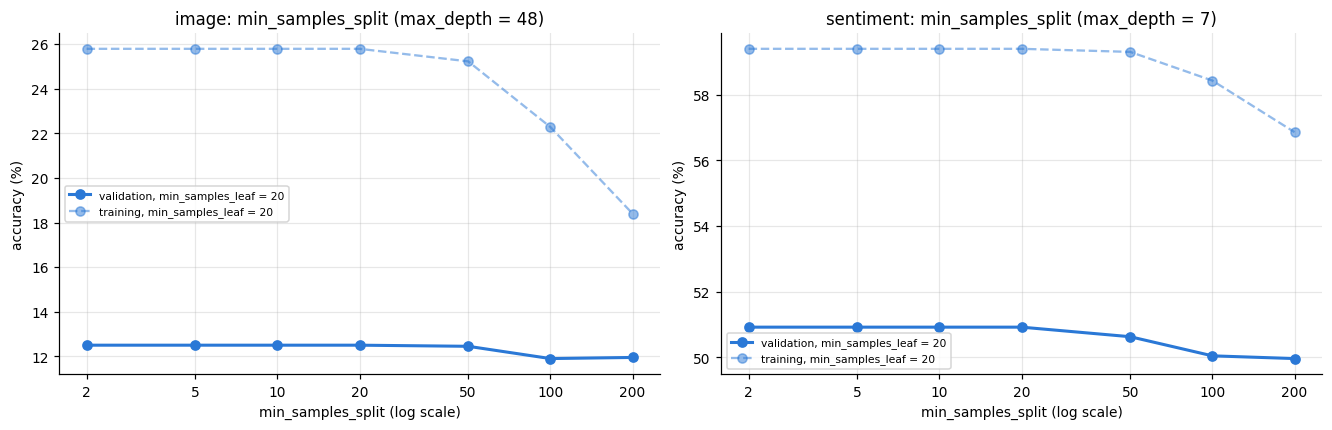

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, task in zip(axes, TASKS):
    table = dt_split[task]
    for leaf, color in zip(sorted(table["min_samples_leaf"].unique()), (BLUE, ORANGE)):
        t = table[table["min_samples_leaf"] == leaf]
        ax.plot(t["min_samples_split"], 100 * t["val_acc"], "o-", color=color, label=f"validation, min_samples_leaf = {leaf}")
        ax.plot(t["min_samples_split"], 100 * t["train_acc"], "o--", color=color, alpha=0.5, linewidth=1.5,
                label=f"training, min_samples_leaf = {leaf}")
    ax.set_xscale("log")
    ax.set_xticks(DT_SPLITS, [str(s) for s in DT_SPLITS])
    ax.minorticks_off()
    ax.set(title=f"{task}: min_samples_split (max_depth = {data[task]['dt_best']['max_depth']})",
           xlabel="min_samples_split (log scale)", ylabel="accuracy (%)")
    ax.legend(fontsize=7)
plt.show()

### 6.5 Does binning cost accuracy? (`n_bins`)

`n_bins` is a hyperparameter of *our implementation*, not of decision trees in general. We retrain the best single tree with 16, 32, 64 and 128 bins. If 64 bins is about as accurate as 128 but faster, it supports our choice (4.2). Accuracy differences smaller than the 95% interval from section 3 (±1.3% for image, ±2% for sentiment) are just noise.

In [36]:
# ===== Section 6.5: number of bins =====
if RUN_BIN_EXPERIMENT:
    bin_rows = []
    for task in TASKS:
        ds = data[task]
        for nb in (16, 32, 64, 128):
            t0 = time.time()
            b_binner = QuantileBinner(nb).fit(ds["X"][ds["tr"]])      # new cut points with nb bins (training rows only)
            tree = DecisionTree(ds["K"], nb, **ds["dt_best"]).fit(b_binner.transform(ds["X"][ds["tr"]]), ds["y_tr"])
            val_acc = accuracy(ds["y_va"], tree.predict(b_binner.transform(ds["X"][ds["va"]])))
            bin_rows.append(dict(task=task, n_bins=nb, val_acc=round(val_acc, 4), seconds=round(time.time() - t0, 1)))
    display(pd.DataFrame(bin_rows).pivot(index="n_bins", columns="task", values=["val_acc", "seconds"]))
else:
    print("skipped (RUN_BIN_EXPERIMENT = False)")

val_acc           seconds          
task     image sentiment   image sentiment
n_bins                                    
16      0.1172    0.4804     5.1       1.7
32      0.1103    0.4629     8.6       2.2
64      0.1250    0.5092    14.6       2.9
128     0.1217    0.4625    31.6       4.3

## 7. The random forest

### 7.1 How a random forest works

A single deep tree has **low bias but high variance**: change the training rows a little and you get a quite different tree (section 6: a full tree gets close to 100% on its training rows but much less on validation). A random forest reduces this variance by **averaging many different trees**:

1. **Bootstrap sample (bagging = bootstrap aggregating):** every tree is trained on $n$ rows drawn *with replacement* from the $n$ training rows. A bootstrap sample contains on average about 63.2% of the distinct rows ($1 - (1 - 1/n)^n \approx 1 - 1/e$), some of them several times. The ~36.8% of rows a tree never saw are its **out-of-bag (OOB)** rows.
2. **Random features at every split:** every split only looks at `max_features` randomly chosen features (default $\sqrt{d}$: 22 of 500 for image, 28 of 768 for sentiment). Without this, every tree would use the same strongest features near the root and all trees would look alike.
3. **Grow every tree deep** (usually no depth limit). Each tree overfits on its own, but they overfit in *different* ways.
4. **Vote:** we average the class shares (`predict_proba`) of all trees and predict the class with the highest average ("soft voting"). Compared with counting hard votes, this also uses how sure each tree is, and it rarely has ties.

**Why averaging helps.** If each tree's prediction has variance $\sigma^2$ and two trees have correlation $\rho$, the average of $B$ trees has variance
$$\rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2 .$$
More trees shrink the second part; bootstrapping and random features make the trees less correlated, which shrinks the first part. A smaller `max_features` gives more different (less correlated) trees, but every tree gets weaker because it may not see the best feature at a split. That trade-off is why we tune `max_features`.

**Out-of-bag accuracy.** For every training row we only let the trees that did *not* see that row vote, and check if the vote is right. It's a free validation set computed from the training rows only. It is a bit pessimistic, because each row is voted on by only ~37% of the trees (with 30 trees that's only ~11 trees per row).

**More trees never makes a forest overfit more.** Adding trees only makes the average more stable: accuracy goes up and then flattens. So `n_estimators` is a cost/benefit choice (time vs a tiny gain), not a bias/variance one.

### 7.2 Our implementation

* `RandomForest` reuses our `DecisionTree`. The bootstrap sample is passed to `fit` as `rows` (so the data is never copied), and `max_features` makes the tree draw random features at each split.
* Every tree gets **its own random seed**, all drawn from the forest's seed. So the forest is exactly the same whether its trees are trained one after the other or 4 at a time on different CPU cores (`n_jobs`).
* While it's being trained, every tree also predicts its own out-of-bag rows. That gives the OOB accuracy, and the OOB accuracy after 1, 2, 3, ... trees (used in 8.2), at almost no extra cost.
* `bootstrap=False` gives every tree all the rows (only the random features make the trees different, and there are no OOB rows). We use it as an experiment to check that bagging actually helps.
* The forest's feature importance is the average of its trees' importances.

In [37]:
# ===== Section 7.2: our random forest =====
def grow_forest_tree(Xb, y, tree_seed, tree_params, bootstrap):
    """Grow ONE tree of a forest. It's a separate function so that joblib can run several of them at the same time.
    Returns the tree, its out-of-bag rows, and its predictions for those rows."""
    rng = np.random.default_rng(tree_seed)
    n = len(y)
    rows = rng.integers(0, n, size=n) if bootstrap else np.arange(n)
    tree = DecisionTree(rng=rng, **tree_params).fit(Xb, y, rows=rows)
    in_bag = np.zeros(n, dtype=bool)
    in_bag[rows] = True
    oob_rows = np.flatnonzero(~in_bag)
    oob_proba = tree.predict_proba(Xb[oob_rows]) if len(oob_rows) else np.zeros((0, tree.K), dtype=np.float32)
    tree.rng = None
    return tree, oob_rows, oob_proba


class RandomForest:
    """Random forest made of our DecisionTree. The hyperparameter names are the same as in scikit-learn."""

    def __init__(self, n_classes, n_estimators=100, n_bins=64, criterion="gini", max_depth=None,
                 min_samples_split=2, min_samples_leaf=1, max_features="sqrt", bootstrap=True, n_jobs=1, seed=42):
        self.K = n_classes
        self.n_estimators = n_estimators
        self.B = n_bins
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.bootstrap = bootstrap
        self.n_jobs = n_jobs
        self.seed = seed

    def fit(self, Xb, y):
        n, d = Xb.shape
        m = self.max_features
        if m == "sqrt":
            m = max(1, int(round(np.sqrt(d))))
        elif m is None:
            m = d
        self.features_per_split = int(m)

        tree_params = dict(n_classes=self.K, n_bins=self.B, criterion=self.criterion, max_depth=self.max_depth,
                           min_samples_split=self.min_samples_split, min_samples_leaf=self.min_samples_leaf,
                           max_features=self.features_per_split)

        # One seed per tree, so the forest is repeatable
        tree_seeds = np.random.default_rng(self.seed).integers(0, 2**31 - 1, size=self.n_estimators)

        start = time.time()
        if HAVE_JOBLIB and self.n_jobs > 1:
            results = Parallel(n_jobs=self.n_jobs)(
                delayed(grow_forest_tree)(Xb, y, s, tree_params, self.bootstrap) for s in tree_seeds)
        else:
            results = [grow_forest_tree(Xb, y, s, tree_params, self.bootstrap) for s in tree_seeds]

        self.fit_seconds = time.time() - start
        self.trees = [tree for tree, _, _ in results]

        # Out-of-bag predictions and accuracy after each tree (used in section 8.2)
        oob_votes = np.zeros((n, self.K))
        oob_count = np.zeros(n, dtype=np.int64)
        self.oob_curve = []

        for _, oob_rows, oob_proba in results:
            oob_votes[oob_rows] += oob_proba
            oob_count[oob_rows] += 1
            seen = oob_count > 0
            self.oob_curve.append(float((oob_votes[seen].argmax(axis=1) == y[seen]).mean()) if seen.any() else np.nan)

        self.oob_accuracy = self.oob_curve[-1]
        return self

    def predict_proba(self, Xb):
        """Average of the class shares of all the trees (soft voting)."""
        total = np.zeros((len(Xb), self.K))
        for tree in self.trees:
            total += tree.predict_proba(Xb)
        return total / len(self.trees)

    def predict(self, Xb):
        return self.predict_proba(Xb).argmax(axis=1)

    def staged_accuracy(self, Xb, y):
        """Accuracy when only the first 1, 2, 3, ... trees vote."""
        total = np.zeros((len(Xb), self.K))
        scores = []
        for tree in self.trees:
            total += tree.predict_proba(Xb)
            scores.append(float((total.argmax(axis=1) == y).mean()))
        return scores


# Check: a 1-tree forest without bootstrap and using all features = our decision tree
one_tree_forest = RandomForest(K_t, n_estimators=1, n_bins=N_BINS, max_features=None, bootstrap=False).fit(Xb_t, y_t)
single_tree = DecisionTree(K_t, N_BINS).fit(Xb_t, y_t)
assert np.array_equal(one_tree_forest.predict_proba(Xb_t), single_tree.predict_proba(Xb_t))
print("check passed: a 1-tree forest without randomness = our decision tree")

check passed: a 1-tree forest without randomness = our decision tree


## 8. Choosing the hyperparameters of the random forest

**Why not a full grid?** With the values in section 1 a full grid would be 5 × 5 × 5 × 4 × 2 × 2 = 2000 forests per task, and one image forest takes around a minute. So we use **one-at-a-time tuning** (also called coordinate search):

1. Start from the usual defaults (the same as scikit-learn): `max_features = sqrt(d)`, `min_samples_leaf = 1`, `max_depth = None`, `min_samples_split = 2`, `criterion = gini`, `bootstrap = True`.
2. Try every value of **one** hyperparameter with the others fixed, and keep the value with the best validation accuracy.
3. Go to the next hyperparameter, using the values chosen so far.

**The order** goes from most to least important for a forest:
* `max_features` first: it decides how different the trees are, which is the whole idea of a random forest (7.1).
* then the tree-size controls `min_samples_leaf`, `max_depth`, `min_samples_split`: a forest usually wants deep trees, but a bit of smoothing can help on noisy data.
* then `criterion` (gini vs entropy again, now inside a forest),
* and `bootstrap` last, as an experiment: "does bagging actually help, or are the random features enough?" Bootstrapping makes the trees more different, but each tree only sees ~63% of the distinct rows, which hurts when there is little data per class (image: 320 rows per class). So the answer is not obvious, and we let the validation set decide. If `False` wins we lose the OOB estimate, but the forest is still a random forest (random features at every split); scikit-learn has the same option.

That's 18 forests per task instead of 2000 (values already trained in an earlier step are not trained again). The downside: it can miss interactions (a value that's only good together with another value of a different hyperparameter). We accept that limitation and mention it in section 15.

**Small forests for tuning.** Each setting is compared with a forest of only 30 trees. To *compare* settings we don't need the full forest: the ranking of settings is usually stable after a few dozen trees (8.2 shows how accuracy grows with the number of trees). For each setting we record the validation accuracy (used to choose), the OOB accuracy (a second opinion from the training rows), the training accuracy, the average tree size and the time.

**`n_estimators` is chosen last** (8.2), from the accuracy-vs-number-of-trees curve of the final forest.

In [46]:


# ===== Section 8.1: one-at-a-time tuning of the forest =====
def forest_scores(ds, params, n_trees):
    """Train a forest on the training rows and return its scores (one row of the tuning table)."""
    forest = RandomForest(ds["K"], n_trees, N_BINS, n_jobs=N_JOBS, seed=SEED, **params).fit(ds["Xb_tr"], ds["y_tr"])
    return dict(val_acc=accuracy(ds["y_va"], forest.predict(ds["Xb_va"])),
                oob_acc=forest.oob_accuracy,
                train_acc=accuracy(ds["y_tr"], forest.predict(ds["Xb_tr"])),
                seconds=round(forest.fit_seconds, 1))


rf_tuning = {}
for task in TASKS:
    ds = data[task]
    d = ds["Xb_tr"].shape[1]
    current = dict(max_features=int(round(np.sqrt(d))), min_samples_leaf=1, max_depth=None,   # start = usual defaults
                   min_samples_split=2, criterion="gini", bootstrap=True)
    rows = []
    t_task = time.time()
    for name, values in RF_SEARCH.items():
        if name == "max_features":      # the list holds multiples of sqrt(d) -> turn them into numbers of features
            values = sorted({max(1, int(round(mult * np.sqrt(d)))) for mult in values})
        step = []
        for value in values:
            params = dict(current, **{name: value})
            result = dict(hyperparameter=name, value=value,
              **forest_scores(ds, params, RF_TUNE_TREES))
            step.append(result)

            print(f"[{task}] {name:>17} = {str(value):>5} -> val {result['val_acc']:.4f}  OOB {result['oob_acc']:.4f}  ")

        best = max(step, key=lambda r: r["val_acc"])    # exact tie -> the first value in the list is kept
        for r in step:
            r["chosen"] = r is best
        current[name] = best["value"]
        rows += step
        print(f"[{task}]   -> keep {name} = {best['value']}")
        warn_if_edge(name, best["value"], values)
        print()
    ds["rf_best"] = current
    rf_tuning[task] = pd.DataFrame(rows)
    print(f"[{task}] FINAL forest settings: {current}  ({time.time() - t_task:.0f}s)\n")

[image]      max_features =     6 -> val 0.1797  OOB 0.1208  
[image]      max_features =    11 -> val 0.2000  OOB 0.1346  
[image]      max_features =    22 -> val 0.1975  OOB 0.1447  
[image]      max_features =    45 -> val 0.2122  OOB 0.1589  
[image]      max_features =    89 -> val 0.2150  OOB 0.1654  
[image]   -> keep max_features = 89
   NOTE: max_features = 89 is the LARGEST value we tried, a bigger value might be even better

[image]  min_samples_leaf =     1 -> val 0.2150  OOB 0.1654  
[image]  min_samples_leaf =     3 -> val 0.2253  OOB 0.1703  
[image]  min_samples_leaf =     5 -> val 0.2293  OOB 0.1807  
[image]  min_samples_leaf =    10 -> val 0.2188  OOB 0.1801  
[image]  min_samples_leaf =    20 -> val 0.2062  OOB 0.1723  
[image]   -> keep min_samples_leaf = 5

[image]         max_depth =     8 -> val 0.1355  OOB 0.1164  
[image]         max_depth =    12 -> val 0.1537  OOB 0.1399  
[image]         max_depth =    16 -> val 0.1802  OOB 0.1529  
[image]         max_dep

In the plots below, every panel is one step of the tuning: the validation accuracy (with its 95% interval) and the OOB accuracy for every value tried. The black star is the value we kept. When the error bars of two values overlap a lot, the difference between them is not really meaningful; then the choice matters little and we could also prefer the cheaper setting (the time is in the table under the plot).

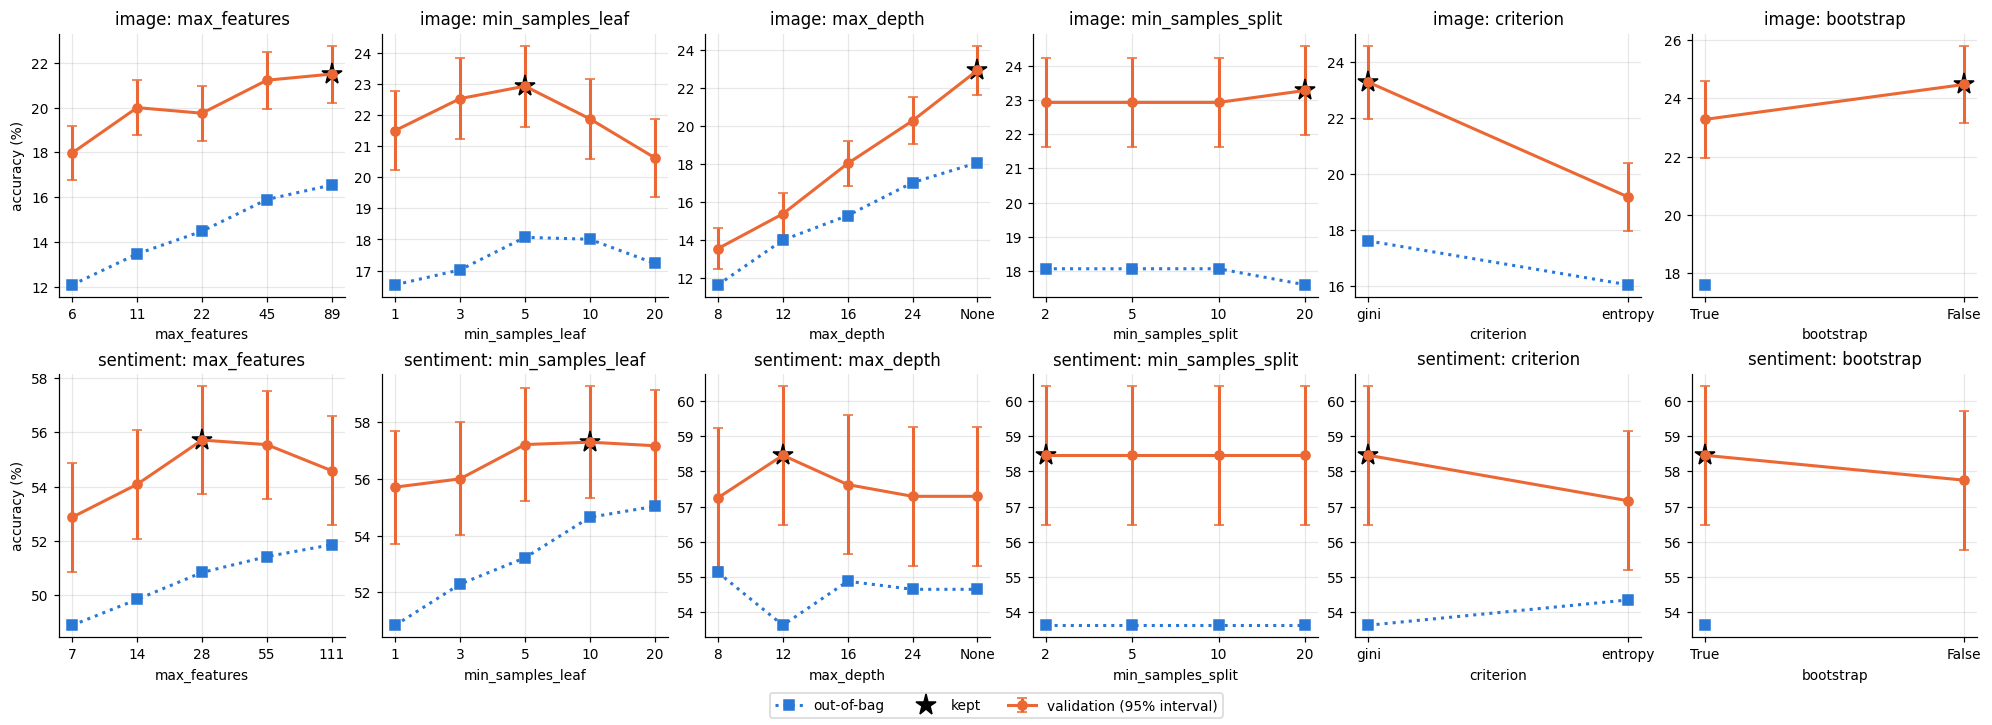

[image] tuning table


,hyperparameter,value,val_acc,oob_acc,train_acc,seconds,chosen
0,max_features,6,0.1798,0.1208,1.0000,29.5,False
1,max_features,11,0.2000,0.1346,1.0000,34.5,False
2,max_features,22,0.1975,0.1448,1.0000,43.8,False
3,max_features,45,0.2122,0.1589,1.0000,66.4,False
4,max_features,89,0.2150,0.1654,1.0000,111.4,True
5,min_samples_leaf,1,0.2150,0.1654,1.0000,116.4,False
6,min_samples_leaf,3,0.2252,0.1703,0.9989,88.0,False
7,min_samples_leaf,5,0.2292,0.1807,0.9931,67.0,True
8,min_samples_leaf,10,0.2188,0.1801,0.9450,45.0,False
9,min_samples_leaf,20,0.2062,0.1723,0.7903,29.7,False


[sentiment] tuning table


,hyperparameter,value,val_acc,oob_acc,train_acc,seconds,chosen
0,max_features,7,0.5288,0.4891,1.0000,6.9,False
1,max_features,14,0.5408,0.4985,0.9998,7.5,False
2,max_features,28,0.5571,0.5084,1.0000,8.6,True
3,max_features,55,0.5554,0.5143,0.9999,10.9,False
4,max_features,111,0.5458,0.5186,1.0000,16.0,False
5,min_samples_leaf,1,0.5571,0.5084,1.0000,8.3,False
6,min_samples_leaf,3,0.5600,0.5229,0.9994,6.9,False
7,min_samples_leaf,5,0.5721,0.5322,0.9960,6.0,False
8,min_samples_leaf,10,0.5729,0.5465,0.9732,4.2,True
9,min_samples_leaf,20,0.5717,0.5503,0.9064,2.8,False


In [47]:
names = list(RF_SEARCH)
fig, axes = plt.subplots(len(TASKS), len(names), figsize=(3 * len(names), 6.5), layout="constrained", squeeze=False)
for r, task in enumerate(TASKS):
    ds, table = data[task], rf_tuning[task]
    for c, name in enumerate(names):
        ax = axes[r, c]
        t = table[table["hyperparameter"] == name].reset_index(drop=True)
        x = np.arange(len(t))
        ci = 100 * accuracy_ci(t["val_acc"].to_numpy(), len(ds["y_va"]))
        ax.errorbar(x, 100 * t["val_acc"], yerr=ci, fmt="o-", color=ORANGE, capsize=3, label="validation (95% interval)")
        ax.plot(x, 100 * t["oob_acc"], "s:", color=BLUE, label="out-of-bag")
        chosen = int(np.flatnonzero(t["chosen"].to_numpy())[0])
        ax.plot(x[chosen], 100 * t.loc[chosen, "val_acc"], "*", color="black", markersize=14, label="kept")
        ax.set_xticks(x, [str(v) for v in t["value"]])
        ax.set(title=f"{task}: {name}", xlabel=name)
        if c == 0:
            ax.set_ylabel("accuracy (%)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3)
plt.show()

for task in TASKS:
    print(f"[{task}] tuning table")
    display(rf_tuning[task].round(4))

### 8.2 `n_estimators` (number of trees)

Now we train the forest we keep, with the chosen settings and 200 trees, and plot the validation and OOB accuracy after 1, 2, 3, ... trees. The curve rises fast and then flattens; after that more trees only cost time (training and prediction time grow linearly with the number of trees). The dotted line marks the number of trees after which accuracy stays within ±0.5 percentage points of the 200-tree value. If that line is far left of 200, 200 trees is more than enough; if it's close to 200, more trees could still help a little.

The OOB curve is lower than the validation curve, especially with few trees: each training row only gets votes from the ~37% of trees that didn't see it, so the OOB "forest" is effectively a smaller forest. (If the tuning in 8.1 chose `bootstrap = False`, every tree sees every row, so there are no out-of-bag rows and no OOB curve.)

[image] 200 trees in 404s: validation 0.2908, no OOB (bootstrap=False)
[sentiment] 200 trees in 25s: validation 0.6000, OOB 0.6041


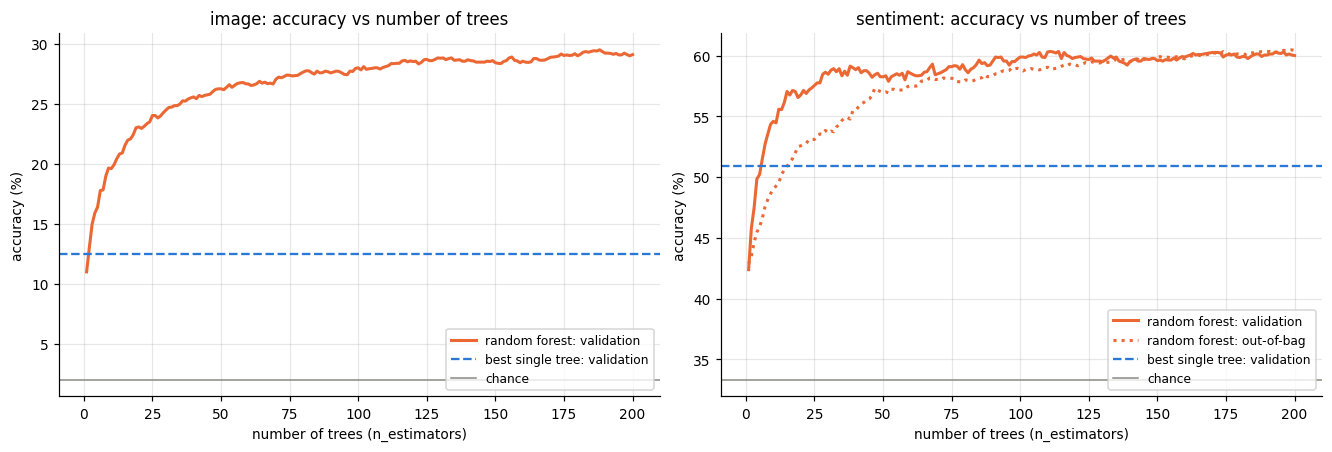

In [48]:
# ===== Section 8.2: the final forest (trained on the training rows) and the number of trees =====
final_forests = {}
for task in TASKS:
    ds = data[task]
    forest = RandomForest(ds["K"], RF_FINAL_TREES, N_BINS, n_jobs=N_JOBS, seed=SEED, **ds["rf_best"])
    forest.fit(ds["Xb_tr"], ds["y_tr"])
    final_forests[task] = forest
    curve = np.array(forest.staged_accuracy(ds["Xb_va"], ds["y_va"]))
    ds["rf_val_curve"] = curve
    oob_text = f"OOB {forest.oob_accuracy:.4f}" if forest.bootstrap else "no OOB (bootstrap=False)"
    print(f"[{task}] {RF_FINAL_TREES} trees in {forest.fit_seconds:.0f}s: validation {curve[-1]:.4f}, {oob_text}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, task in zip(axes, TASKS):
    ds, forest = data[task], final_forests[task]
    n_trees = np.arange(1, RF_FINAL_TREES + 1)
    ax.plot(n_trees, 100 * ds["rf_val_curve"], color=ORANGE, label="random forest: validation")
    if forest.bootstrap:
        ax.plot(n_trees, 100 * np.array(forest.oob_curve), color=ORANGE, linestyle=":", label="random forest: out-of-bag")
    ax.axhline(100 * ds["dt_val_acc"], color=BLUE, linestyle="--", linewidth=1.5, label="best single tree: validation")
    ax.axhline(100 / ds["K"], color=GRAY, linewidth=1, label="chance")
    ax.set(title=f"{task}: accuracy vs number of trees", xlabel="number of trees (n_estimators)", ylabel="accuracy (%)")
    ax.legend(fontsize=8, loc="lower right")
plt.show()

## 9. Decision tree vs random forest

Both models with their chosen settings, trained on the training rows (80%) and scored on the validation rows (20%). Besides accuracy we show:
* **macro-F1**: the F1 score of every class, averaged. With balanced classes it's close to accuracy, but it would drop if a model ignored some classes.
* **gap = training - validation accuracy**: a big gap means the model memorised the training rows (overfitting).
* **× chance**: validation accuracy divided by chance accuracy, so the two tasks can be compared fairly (50 classes vs 3).

In [50]:
# ===== Section 9: compare the two models =====
final_trees = {}
comparison = []
for task in TASKS:
    ds = data[task]
    t0 = time.time()
    tree = DecisionTree(ds["K"], N_BINS, **ds["dt_best"]).fit(ds["Xb_tr"], ds["y_tr"])
    tree_seconds = time.time() - t0
    final_trees[task] = tree
    forest = final_forests[task]
    ds["dt_proba_va"] = tree.predict_proba(ds["Xb_va"])     # kept for the error analysis in section 10
    ds["rf_proba_va"] = forest.predict_proba(ds["Xb_va"])
    for model, proba_va, train_pred, seconds, oob in (
            ("Decision Tree", ds["dt_proba_va"], tree.predict(ds["Xb_tr"]), tree_seconds, np.nan),
            ("Random Forest", ds["rf_proba_va"], forest.predict(ds["Xb_tr"]), forest.fit_seconds, forest.oob_accuracy)):
        pred = proba_va.argmax(axis=1)
        val_acc, train_acc = accuracy(ds["y_va"], pred), accuracy(ds["y_tr"], train_pred)
        comparison.append(dict(task=task, model=model, val_acc=val_acc, ci95=accuracy_ci(val_acc, len(pred)),
                               val_macro_f1=macro_f1(confusion_matrix(ds["y_va"], pred, ds["K"])),
                               train_acc=train_acc, gap=train_acc - val_acc, oob_acc=oob,
                               times_chance=val_acc * ds["K"], train_seconds=round(seconds, 1)))
comparison = pd.DataFrame(comparison)
display(comparison.round(4))
print("Average validation accuracy over the two tasks (both Kaggle test sets have 5000 rows, so this is our estimate of the Kaggle score):")
print(comparison.groupby("model")["val_acc"].mean().map(lambda v: f"{v:.2%}").to_string())

,task,model,val_acc,ci95,val_macro_f1,train_acc,gap,oob_acc,times_chance,train_seconds
0,image,Decision Tree,0.1250,0.0102,0.1248,0.2579,0.1329,NaN,6.2500,14.5
1,image,Random Forest,0.2908,0.0141,0.2799,0.9884,0.6976,NaN,14.5375,403.6
2,sentiment,Decision Tree,0.5092,0.0200,0.5068,0.5941,0.0849,NaN,1.5275,1.9
3,sentiment,Random Forest,0.6000,0.0196,0.5969,0.9812,0.3812,0.6041,1.8000,24.7


Average validation accuracy over the two tasks (both Kaggle test sets have 5000 rows, so this is our estimate of the Kaggle score):
model
Decision Tree    31.71%
Random Forest    44.54%


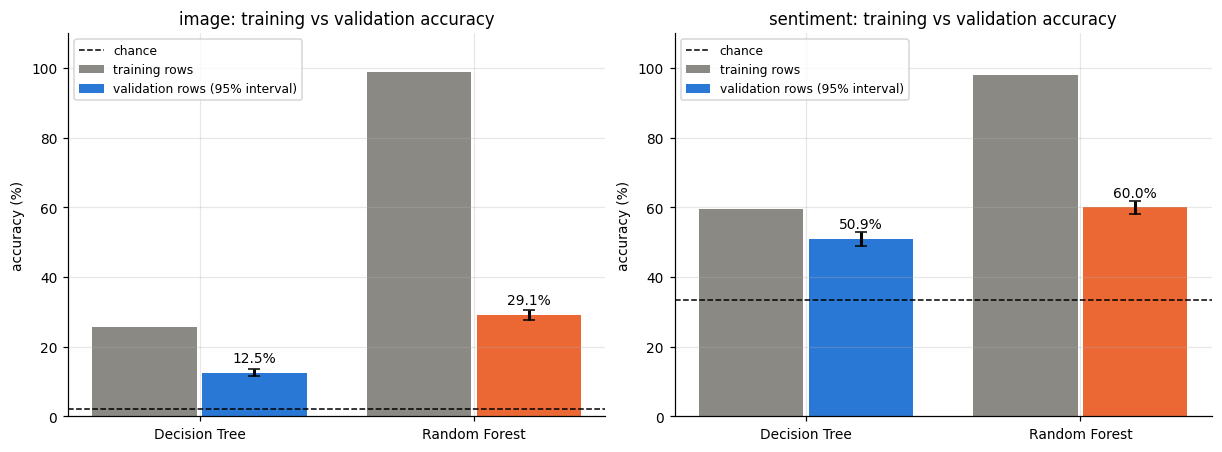

[image] both right 9.6% | only the forest right 19.5% | only the tree right 2.9% | both wrong 68.0%
[sentiment] both right 38.8% | only the forest right 21.2% | only the tree right 12.2% | both wrong 27.8%


In [51]:
# Training vs validation accuracy of both models. The gap between the grey and the coloured bar = overfitting.
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, task in zip(axes, TASKS):
    t = comparison[comparison["task"] == task].reset_index(drop=True)
    x = np.arange(len(t))
    ax.bar(x - 0.2, 100 * t["train_acc"], width=0.38, color=GRAY, label="training rows")
    ax.bar(x + 0.2, 100 * t["val_acc"], width=0.38, yerr=100 * t["ci95"], capsize=4, color=[BLUE, ORANGE],
           label="validation rows (95% interval)")
    for xi, v in zip(x, t["val_acc"]):
        ax.text(xi + 0.2, 100 * v + 3, f"{v:.1%}", ha="center", fontsize=9)
    ax.axhline(100 / data[task]["K"], color="black", linestyle="--", linewidth=1, label="chance")
    ax.set_xticks(x, t["model"])
    ax.set_ylim(0, 110)
    ax.set(title=f"{task}: training vs validation accuracy", ylabel="accuracy (%)")
    ax.legend(fontsize=8, loc="upper left")
plt.show()

# Where do the two models agree / disagree?
for task in TASKS:
    ds = data[task]
    dt_ok = ds["dt_proba_va"].argmax(axis=1) == ds["y_va"]
    rf_ok = ds["rf_proba_va"].argmax(axis=1) == ds["y_va"]
    print(f"[{task}] both right {np.mean(dt_ok & rf_ok):.1%} | only the forest right {np.mean(rf_ok & ~dt_ok):.1%} | "
          f"only the tree right {np.mean(dt_ok & ~rf_ok):.1%} | both wrong {np.mean(~dt_ok & ~rf_ok):.1%}")

## 10. Examples of model errors

Our features are numbers (image features and text embeddings), not the pictures or texts themselves, so we can't show the actual picture that was misclassified. Instead we look at the errors in four ways:
1. **Confusion matrices**: which classes get mixed up with which.
2. **Accuracy per class** (image): are some classes much harder than others?
3. **Confidence**: is the forest less sure when it's wrong? And is the right answer at least among its top guesses?
4. **Concrete examples**: the validation rows where the forest was most confident and still wrong, with their ids so we can look them up.

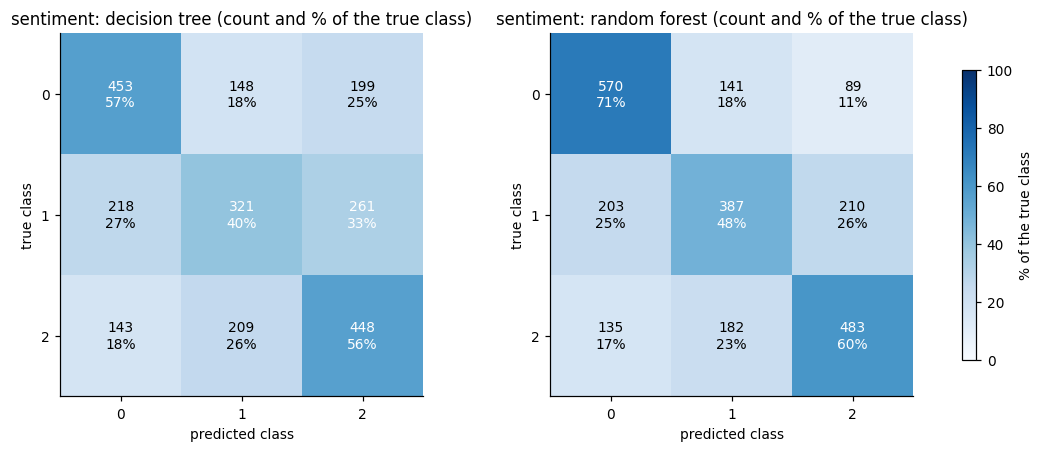

In [52]:
# ===== Section 10.1: confusion matrices =====
def plot_confusion(ax, cm, title, annotate=True, vmax=None):
    """Confusion matrix as a heatmap. Every row is divided by its total, so a cell = % of that true class."""
    share = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    im = ax.imshow(100 * share, cmap="Blues", vmin=0, vmax=100 * (share.max() if vmax is None else vmax))
    if annotate:
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, f"{cm[i, j]}\n{share[i, j]:.0%}", ha="center", va="center", fontsize=9,
                        color="white" if share[i, j] > 0.5 * share.max() else "black")
    ax.grid(False)
    ax.set(title=title, xlabel="predicted class", ylabel="true class")
    return im


# Sentiment: 3 x 3, both models, with the numbers written in the cells
ds = data["sentiment"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, (key, model) in zip(axes, (("dt", "decision tree"), ("rf", "random forest"))):
    cm = confusion_matrix(ds["y_va"], ds[f"{key}_proba_va"].argmax(axis=1), ds["K"])
    im = plot_confusion(ax, cm, f"sentiment: {model} (count and % of the true class)", vmax=1)
    ax.set_xticks(range(ds["K"]), ds["classes"])
    ax.set_yticks(range(ds["K"]), ds["classes"])
fig.colorbar(im, ax=axes, label="% of the true class", shrink=0.8)
plt.show()

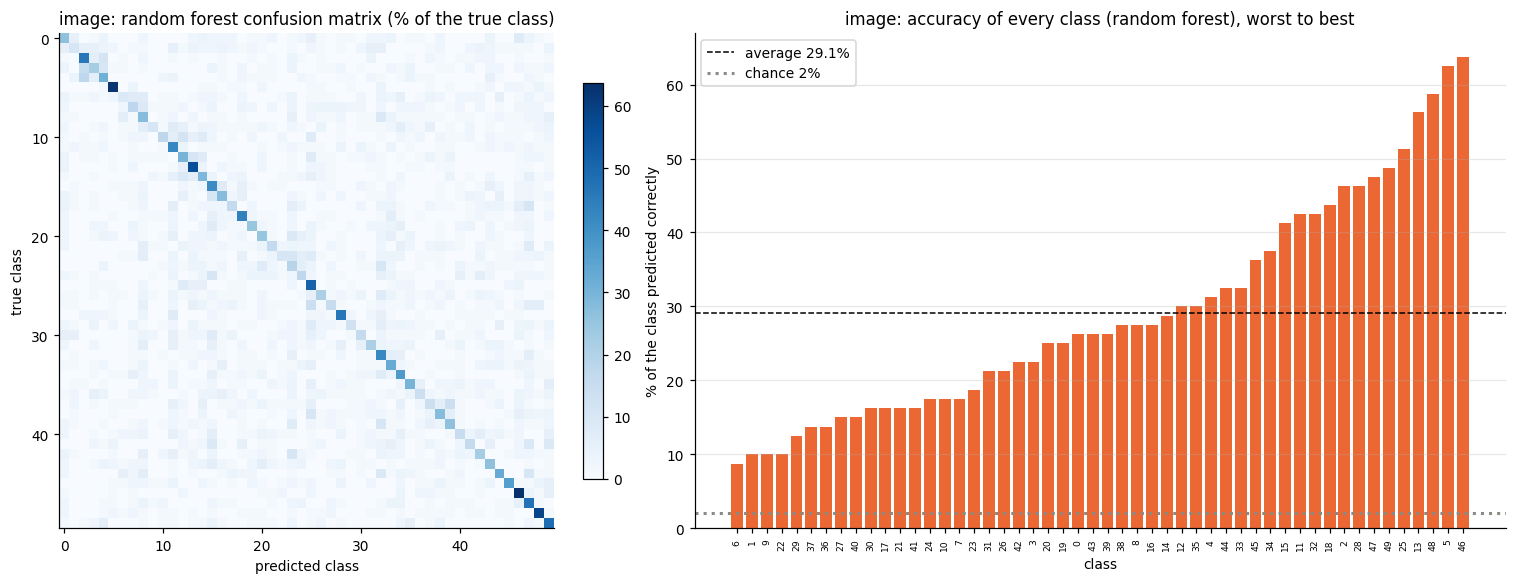

image: the 10 most frequent mistakes of the random forest on the validation rows


,true_class,predicted_as,rows,share_of_true_class,opposite_mistake_rows
0,4,2,14,18%,9
1,3,2,12,15%,5
2,37,39,11,14%,4
3,27,25,11,14%,1
4,10,12,9,11%,1
5,2,4,9,11%,14
6,22,23,8,10%,1
7,12,13,8,10%,4
8,39,32,8,10%,0
9,24,15,8,10%,0


In [53]:
# Image: 50 x 50 is too big for numbers, so a heatmap of the forest + the accuracy of every class, sorted
ds = data["image"]
pred = ds["rf_proba_va"].argmax(axis=1)
cm_img = confusion_matrix(ds["y_va"], pred, ds["K"])
recall = np.diag(cm_img) / cm_img.sum(axis=1)          # accuracy inside each true class
order = np.argsort(recall)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), layout="constrained", gridspec_kw={"width_ratios": [1, 1.4]})
im = plot_confusion(axes[0], cm_img, "image: random forest confusion matrix (% of the true class)", annotate=False)
fig.colorbar(im, ax=axes[0], shrink=0.8)
axes[1].bar(np.arange(ds["K"]), 100 * recall[order], color=ORANGE)
axes[1].axhline(100 * recall.mean(), color="black", linestyle="--", linewidth=1, label=f"average {recall.mean():.1%}")
axes[1].axhline(100 / ds["K"], color=GRAY, linestyle=":", label=f"chance {1 / ds['K']:.0%}")
axes[1].set_xticks(np.arange(ds["K"]), ds["classes"][order], fontsize=6, rotation=90)
axes[1].set(title="image: accuracy of every class (random forest), worst to best", xlabel="class",
            ylabel="% of the class predicted correctly")
axes[1].grid(axis="x", visible=False)
axes[1].legend()
plt.show()

# The 10 most common mistakes (true class -> predicted class), and how often the opposite mistake happens
off_diagonal = cm_img.copy()
np.fill_diagonal(off_diagonal, 0)
top = np.argsort(off_diagonal.ravel())[::-1][:10]
pairs = [dict(true_class=ds["classes"][i], predicted_as=ds["classes"][j], rows=int(off_diagonal[i, j]),
              share_of_true_class=f"{off_diagonal[i, j] / cm_img[i].sum():.0%}",
              opposite_mistake_rows=int(off_diagonal[j, i]))
         for i, j in zip(*np.unravel_index(top, off_diagonal.shape))]
print("image: the 10 most frequent mistakes of the random forest on the validation rows")
display(pd.DataFrame(pairs))

In [54]:
# todo delete 
# # ===== Section 10.2: how sure is the forest when it is right vs when it is wrong? =====
# fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
# for ax, task in zip(axes, TASKS):
#     ds = data[task]
#     proba = ds["rf_proba_va"]
#     confidence = proba.max(axis=1)                   # the forest's average vote for the class it predicts
#     correct = proba.argmax(axis=1) == ds["y_va"]
#     bins = np.linspace(0, confidence.max(), 40)
#     ax.hist(confidence[correct], bins=bins, color=AQUA, alpha=0.6, label=f"correct ({correct.mean():.0%} of rows)")
#     ax.hist(confidence[~correct], bins=bins, color=ORANGE, alpha=0.6, label=f"wrong ({(~correct).mean():.0%} of rows)")
#     ax.set(title=f"{task}: forest confidence on validation rows", xlabel="share of the vote for the predicted class",
#            ylabel="validation rows")
#     ax.legend(fontsize=8)

#     # accuracy for the 20% most / least confident rows, and "is the true class among the top-k guesses?"
#     most, least = confidence >= np.quantile(confidence, 0.8), confidence <= np.quantile(confidence, 0.2)
#     true_score = proba[np.arange(len(proba)), ds["y_va"]]
#     rank_of_true = (proba > true_score[:, None]).sum(axis=1)          # 0 = the true class is the top guess
#     top_k = ", ".join(f"top-{k} {np.mean(rank_of_true < k):.1%}" for k in (1, 3, 5) if k < ds["K"])
#     print(f"[{task}] accuracy on the 20% most confident rows {correct[most].mean():.1%}, "
#           f"on the 20% least confident rows {correct[least].mean():.1%} | true class among the forest's {top_k}")
# plt.show()

In [55]:
# ===== Section 10.3: concrete examples: the most confident mistakes =====
for task in TASKS:
    ds = data[task]
    proba = ds["rf_proba_va"]
    pred = proba.argmax(axis=1)
    wrong = np.flatnonzero(pred != ds["y_va"])
    worst = wrong[np.argsort(-proba[wrong, pred[wrong]])][:8]        # wrong rows sorted by confidence, highest first
    examples = pd.DataFrame({
        "id": ds["ids"][ds["va"][worst]],
        "true label": ds["classes"][ds["y_va"][worst]],
        "forest predicted": ds["classes"][pred[worst]],
        "forest vote for its prediction": proba[worst, pred[worst]].round(3),
        "forest vote for the true label": proba[worst, ds["y_va"][worst]].round(3),
        "single tree predicted": ds["classes"][ds["dt_proba_va"][worst].argmax(axis=1)],
    })
    print(f"[{task}] the random forest's most confident mistakes on the validation rows:")
    display(examples)

[image] the random forest's most confident mistakes on the validation rows:


,id,true label,forest predicted,forest vote for its prediction,forest vote for the true label,single tree predicted
0,img_train_018498,25,5,0.593,0.027,5
1,img_train_001122,13,5,0.545,0.013,5
2,img_train_012616,20,43,0.510,0.006,43
3,img_train_007502,6,5,0.509,0.015,5
4,img_train_001780,3,2,0.491,0.188,2
5,img_train_018875,44,47,0.477,0.048,47
6,img_train_015989,3,2,0.470,0.182,2
7,img_train_003833,3,2,0.466,0.196,2


[sentiment] the random forest's most confident mistakes on the validation rows:


,id,true label,forest predicted,forest vote for its prediction,forest vote for the true label,single tree predicted
0,text_train_004692,1,0,0.724,0.184,0
1,text_train_004381,1,0,0.723,0.186,0
2,text_train_003455,1,0,0.720,0.190,0
3,text_train_000130,1,0,0.717,0.168,0
4,text_train_008876,1,0,0.705,0.173,0
5,text_train_010716,1,0,0.696,0.186,0
6,text_train_011896,0,2,0.679,0.110,2
7,text_train_004136,2,1,0.674,0.225,1


**How to read the error analysis:**
* For sentiment, look at which pair of classes is confused most. Usually the "middle" class (if one class is neutral) gets mixed up with both sides, while the two extreme classes are rarely confused with each other.
* For image, the per-class bar chart shows that some classes are much easier than others, and the most frequent mistakes table shows which pairs of classes look alike *in these features*. If a mistake happens in both directions (A → B and B → A), the two classes really overlap in feature space.
* The confidence histogram shows that mistakes mostly happen when the vote is split: the forest "knows" when it's unsure. The top-k numbers show that for image many mistakes are near misses (the true class is among the top few guesses).
* The most confident mistakes are worth looking at by id: they can be mislabeled examples or examples that really look like another class.

## 11. Overfitting and underfitting

### 11.1 Learning curves

A learning curve shows training and validation accuracy when the model is trained on 10%, 25%, 50%, 75% and 100% of our training rows (same hyperparameters, same validation rows; the forest uses 30 trees here to save time):
* validation curve **still going up** at 100% → more data would help (the model is limited by data, i.e. variance);
* training and validation both low and close together → the model is too simple (**underfitting**, high bias);
* a big gap between training and validation → **overfitting**.

[image] trained on 1600 rows
[image] trained on 4000 rows
[image] trained on 8000 rows
[image] trained on 12000 rows
[image] trained on 16000 rows
[sentiment] trained on 960 rows
[sentiment] trained on 2400 rows
[sentiment] trained on 4800 rows
[sentiment] trained on 7200 rows
[sentiment] trained on 9600 rows


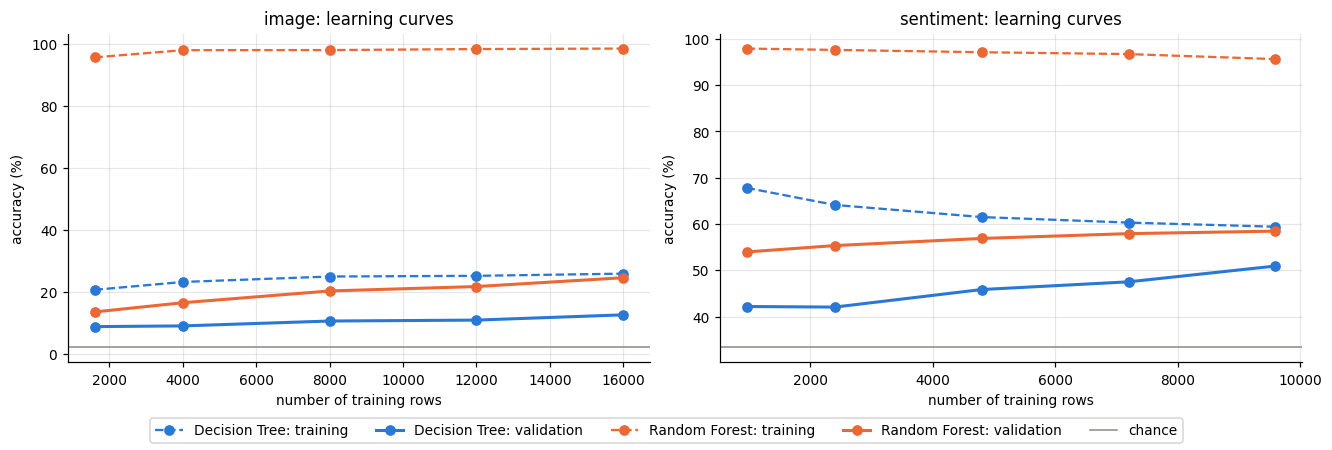

In [56]:
# ===== Section 11.1: learning curves =====
learning = []
for task in TASKS:
    ds = data[task]
    for fraction in LC_FRACTIONS:
        # stratified subsample of the training rows (same function as the validation split: every class keeps its share)
        part = stratified_split(ds["y_tr"], fraction, SEED)[1] if fraction < 1 else np.arange(len(ds["y_tr"]))
        Xb_part, y_part = ds["Xb_tr"][part], ds["y_tr"][part]
        tree = DecisionTree(ds["K"], N_BINS, **ds["dt_best"]).fit(Xb_part, y_part)
        forest = RandomForest(ds["K"], RF_TUNE_TREES, N_BINS, n_jobs=N_JOBS, seed=SEED, **ds["rf_best"]).fit(Xb_part, y_part)
        for model, m in (("Decision Tree", tree), ("Random Forest", forest)):
            learning.append(dict(task=task, model=model, train_rows=len(part),
                                 train_acc=accuracy(y_part, m.predict(Xb_part)),
                                 val_acc=accuracy(ds["y_va"], m.predict(ds["Xb_va"]))))
        print(f"[{task}] trained on {len(part)} rows")
learning = pd.DataFrame(learning)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, task in zip(axes, TASKS):
    for model, color in (("Decision Tree", BLUE), ("Random Forest", ORANGE)):
        t = learning[(learning["task"] == task) & (learning["model"] == model)]
        ax.plot(t["train_rows"], 100 * t["train_acc"], "o--", color=color, linewidth=1.5, label=f"{model}: training")
        ax.plot(t["train_rows"], 100 * t["val_acc"], "o-", color=color, label=f"{model}: validation")
    ax.axhline(100 / data[task]["K"], color=GRAY, linewidth=1, label="chance")
    ax.set(title=f"{task}: learning curves", xlabel="number of training rows", ylabel="accuracy (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=5)
plt.show()

### 11.2 Summary: where we see overfitting and underfitting

The cell below prints the actual numbers behind each piece of evidence, so we can quote them in the presentation:
* **Depth curve (6.1):** shallow trees are bad on *both* training and validation rows = underfitting. Very deep trees get close to 100% on training rows but not on validation rows = overfitting.
* **`min_samples_leaf` (6.2):** bigger leaves lower the training accuracy (less memorising) without hurting validation accuracy as much.
* **Train/validation gap (9):** both models have a big gap. For the forest that's expected (each tree is grown deep and has seen ~63% of the rows) and harmless: averaging cancels most of the individual trees' overfitting, which is why its validation accuracy is much higher than one tree's. For a forest we judge with validation/OOB accuracy, never with training accuracy.
* **Number of trees (8.2):** the validation curve flattens but doesn't go down: more trees don't cause overfitting.
* **Learning curves (11.1):** if validation accuracy is still rising at the full training size, more data would help.

In [57]:
# ===== Section 11.2: the numbers for the overfitting / underfitting slide =====
for task in TASKS:
    ds, grid = data[task], dt_grid[task]
    g = grid[(grid["criterion"] == ds["dt_best"]["criterion"]) & (grid["min_samples_leaf"] == 1)].reset_index(drop=True)
    shallow, deep, best = g.iloc[min(1, len(g) - 1)], g.iloc[-1], g.loc[g["val_acc"].idxmax()]
    cmp = comparison[comparison["task"] == task].set_index("model")
    lc = learning[(learning["task"] == task) & (learning["model"] == "Random Forest")]
    print(f"[{task}]")
    print(f"  tree cut at depth {shallow['max_depth']:>3}: training {shallow['train_acc']:6.1%}, validation {shallow['val_acc']:6.1%}  <- underfitting")
    print(f"  tree cut at depth {best['max_depth']:>3}: training {best['train_acc']:6.1%}, validation {best['val_acc']:6.1%}  <- best depth when min_samples_leaf = 1")
    print(f"  full tree, depth  {deep['max_depth']:>3}: training {deep['train_acc']:6.1%}, validation {deep['val_acc']:6.1%}  <- overfitting")
    for model in ("Decision Tree", "Random Forest"):
        print(f"  {model} (chosen settings): training {cmp.loc[model, 'train_acc']:.1%}, validation {cmp.loc[model, 'val_acc']:.1%}, "
              f"gap {cmp.loc[model, 'gap']:.1%}")
    print(f"  forest learning curve: validation {lc['val_acc'].iloc[0]:.1%} with {lc['train_rows'].iloc[0]} rows -> "
          f"{lc['val_acc'].iloc[-1]:.1%} with {lc['train_rows'].iloc[-1]} rows "
          f"(last step: {100 * (lc['val_acc'].iloc[-1] - lc['val_acc'].iloc[-2]):+.1f} points)")

[image]
  tree cut at depth   2: training   3.6%, validation   3.8%  <- underfitting
  tree cut at depth  60: training  93.1%, validation  11.2%  <- best depth when min_samples_leaf = 1
  full tree, depth  109: training 100.0%, validation  11.2%  <- overfitting
  Decision Tree (chosen settings): training 25.8%, validation 12.5%, gap 13.3%
  Random Forest (chosen settings): training 98.8%, validation 29.1%, gap 69.8%
  forest learning curve: validation 13.4% with 1600 rows -> 24.5% with 16000 rows (last step: +2.8 points)
[sentiment]
  tree cut at depth   2: training  43.9%, validation  43.9%  <- underfitting
  tree cut at depth   7: training  60.2%, validation  49.8%  <- best depth when min_samples_leaf = 1
  full tree, depth   22: training 100.0%, validation  45.9%  <- overfitting
  Decision Tree (chosen settings): training 59.4%, validation 50.9%, gap 8.5%
  Random Forest (chosen settings): training 98.1%, validation 60.0%, gap 38.1%
  forest learning curve: validation 54.0% with 960

## 13. Differences between the image task and the sentiment task

The table puts together the numbers from the whole notebook.

In [59]:
# ===== Section 13: the two tasks side by side =====
rows = []
for task in TASKS:
    ds = data[task]
    cmp = comparison[comparison["task"] == task].set_index("model")
    rows.append({
        "task": task,
        "classes": ds["K"],
        "features": ds["X"].shape[1],
        "training rows per class (after the split)": int(len(ds["y_tr"]) / ds["K"]),
        "% of feature values exactly 0": f"{100 * (ds['X'] == 0).mean():.0f}%",
        "chance accuracy": f"{1 / ds['K']:.1%}",
        "best tree settings": str(ds["dt_best"]),
        "best forest settings": str(ds["rf_best"]),
        "tree: validation accuracy": f"{cmp.loc['Decision Tree', 'val_acc']:.1%}",
        "forest: validation accuracy": f"{cmp.loc['Random Forest', 'val_acc']:.1%}",
        "forest: x chance": f"{cmp.loc['Random Forest', 'times_chance']:.1f}x",
        "forest gain over the tree": f"{100 * (cmp.loc['Random Forest', 'val_acc'] - cmp.loc['Decision Tree', 'val_acc']):+.1f} points",
        "forest training time": f"{cmp.loc['Random Forest', 'train_seconds']:.0f}s",
    })
display(pd.DataFrame(rows).set_index("task").T)

task,image,sentiment
classes,50,3
features,500,768
training rows per class (after the split),320,3200
% of feature values exactly 0,85%,0%
chance accuracy,2.0%,33.3%
best tree settings,"{'criterion': 'gini', 'max_depth': 48, 'min_sa...","{'criterion': 'entropy', 'max_depth': 7, 'min_..."
best forest settings,"{'max_features': 89, 'min_samples_leaf': 5, 'm...","{'max_features': 28, 'min_samples_leaf': 10, '..."
tree: validation accuracy,12.5%,50.9%
forest: validation accuracy,29.1%,60.0%
forest: x chance,14.5x,1.8x
